# Detección de Patrones de Fraude en Contratos Públicos (TED 2018-2023)
**TFM** — Máster en Data Science, Big Data y Business Analytics (UCM)
**Tutores**: Carlos Ortega, Santiago Mota

Pipeline completo de ingesta con PySpark, ingeniería de variables (22 red flags OCDE), análisis exploratorio, modelado (MLlib, Keras, scikit-learn), validación de circularidad e interpretabilidad.


## Setup del entorno

In [1]:
import os, sys
# Desactivo oneDNN: reordena las sumas en coma flotante y rompe la
# reproducibilidad con semilla (AUROC del autoencoder variaba ±0,02).
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import warnings
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
# Directorio del proyecto
PROJ_ROOT = Path(os.getcwd()).parent if Path(os.getcwd()).name == 'notebooks' else Path(os.getcwd())

# Configuración de gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# Comprobación del entorno de trabajo
print(f"Ruta actual de trabajo: {PROJ_ROOT}")

Ruta actual de trabajo: /home/thykan/Escritorio/TFM


## Fase 1 — Ingesta y preparación de datos con PySpark

### 1.1 Inicialización del clúster local y carga de fuentes raw

Lectura de los extractos históricos de TED (2018-2023) seleccionando las variables analíticas según el *codebook* v3.6:
- **CAN** (*Contract Award Notices*): ~6,2M registros brutos, 75 columnas (3,9 GB)
- **CN** (*Contract Notices*): ~7,7M registros brutos, 64 columnas (3,6 GB)

El procesamiento descarta licitaciones canceladas (`CANCELLED = 1`), resuelve duplicidades sobre claves compuestas mediante ventanas temporales y consolida ambos orígenes en Parquet mediante *left join* (`ID_NOTICE_CAN = FUTURE_CAN_ID`).

In [2]:
import os, sys
# Spark lanza workers Python separados. Por defecto usan el Python del sistema
# (/usr/bin/python3) que no tiene pyarrow ni las dependencias del venv.
# Fuerzo que usen el mismo Python del venv (env_analytics).
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

# Memoria del driver adaptativa: 48 GB como techo, pero nunca por encima de
# la RAM fisica menos 16 GB (margen para el sistema, el navegador y Jupyter),
# para que el kernel del sistema no tenga que matar la JVM (OOM).
_ram_gb = 32  # supuesto conservador si no se puede medir la RAM
try:
    for _line in open('/proc/meminfo'):
        if _line.startswith('MemTotal:'):
            _ram_gb = int(_line.split()[1]) // 2**20
            break
except OSError:
    pass
driver_mem = f'{max(4, min(48, _ram_gb - 16))}g'

from pyspark.sql import SparkSession

# Creación de la sesión de Spark desactivando la comprobación estricta de headers
spark = (
    SparkSession.builder.appName("TFM_TED_Análisis")
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", driver_mem)
    .config("spark.executor.memory", driver_mem)
    .config("spark.sql.ansi.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

# Definición de rutas a los archivos de datos
raw_dir = os.path.join(PROJ_ROOT, "data", "raw")

path_can = os.path.join(raw_dir, "TED - Contract award notices 2018 - 2023.csv")
path_cn = os.path.join(raw_dir, "TED - Contract notices 2018 - 2023.csv")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/09/09 20:02:17 WARN Utils: Your hostname, thykan, resolves to a loopback address: 127.0.1.1; using 192.168.50.137 instead (on interface eno1)
26/09/09 20:02:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/09 20:02:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
from pyspark.sql import functions as F

# Desactivo el modo estricto de Spark (ANSI mode) por si hay basura que no rompa la ejecución
spark.conf.set("spark.sql.ansi.enabled", "false")

can_raw = spark.read \
    .option("header", "true") \
    .option("nullValue", "") \
    .csv(path_can) \
    .select(
        F.col("ID_NOTICE_CAN").cast("long"),
        F.col("YEAR").cast("integer"),
        F.expr("try_to_date(DT_DISPATCH, 'dd/MM/yy')").alias("DT_DISPATCH"),
        F.col("CANCELLED").cast("integer"),
        F.col("CORRECTIONS").cast("integer"),
        F.col("ISO_COUNTRY_CODE").cast("string"),
        F.col("CAE_NATIONALID").cast("string"),
        F.col("CPV").cast("string"),
        F.col("TOP_TYPE").cast("string"),
        F.col("B_ACCELERATED").cast("string"),
        F.col("OUT_OF_DIRECTIVES").cast("string"),
        F.col("INFO_ON_NON_AWARD").cast("string"),
        F.col("INFO_UNPUBLISHED").cast("string"),
        F.col("LOTS_NUMBER").cast("integer"),
        F.col("VALUE_EURO_FIN_1").cast("double"),
        F.col("AWARD_VALUE_EURO_FIN_1").cast("double"),
        F.col("ID_AWARD").cast("string"),
        F.expr("try_to_date(DT_AWARD, 'dd/MM/yy')").alias("DT_AWARD"),
        F.col("NUMBER_OFFERS").cast("integer"),
        F.col("NUMBER_TENDERS_OTHER_EU").cast("integer"),
        F.col("NUMBER_TENDERS_NON_EU").cast("integer"),
        F.col("WIN_NATIONALID").cast("string"),
        F.col("WIN_COUNTRY_CODE").cast("string"),
        F.col("B_AWARDED_TO_A_GROUP").cast("string")
    )

print(f"CAN cargado: {can_raw.count():,} filas y {len(can_raw.columns)} columnas.")

cn_raw = spark.read \
    .option("header", "true") \
    .option("nullValue", "") \
    .csv(path_cn) \
    .select(
        F.col("ID_NOTICE_CN").cast("long"),
        F.col("CANCELLED").cast("integer"),
        F.col("CORRECTIONS").cast("integer"),
        F.col("FUTURE_CAN_ID").cast("long"),
        F.col("ISO_COUNTRY_CODE").cast("string"),
        F.col("CPV").cast("string"),
        F.col("TOP_TYPE").cast("string"),
        F.col("DURATION").cast("double"),
        F.expr("try_to_date(CONTRACT_START, 'dd/MM/yy')").alias("CONTRACT_START"),
        F.expr("try_to_date(CONTRACT_COMPLETION, 'dd/MM/yy')").alias("CONTRACT_COMPLETION"),
        F.col("VALUE_EURO_FIN_1").cast("double"),
        F.col("LOTS_NUMBER").cast("integer"),
        F.col("ID_LOT").cast("string"),
        F.col("B_VARIANTS").cast("string"),
        F.expr("try_to_date(DT_APPLICATIONS, 'dd/MM/yy')").alias("DT_APPLICATIONS"),
        F.col("ENV_OPERATORS").cast("integer"),
        F.col("ENV_MIN_OPERATORS").cast("integer"),
        F.col("ENV_MAX_OPERATORS").cast("integer"),
        F.col("B_RENEWALS").cast("string"),
        F.col("B_OPTIONS").cast("string")
    )

print(f"CN cargado: {cn_raw.count():,} filas y {len(cn_raw.columns)} columnas.")

CAN cargado: 6,198,063 filas y 24 columnas.


CN cargado: 7,716,823 filas y 20 columnas.


In [4]:
# Limpieza del dataset de Adjudicaciones (CAN) a nivel ID_AWARD
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Filtrado de registros inválidos o cancelados segun las reglas del TED
can_clean = can_raw \
    .filter(F.col("CANCELLED") != 1) \
    .filter(F.col("ID_AWARD").isNotNull() & (F.length(F.trim(F.col("ID_AWARD"))) > 0)) \
    .filter(F.col("ISO_COUNTRY_CODE").isNotNull()) \
    .filter(F.col("CPV").isNotNull()) \
    .filter(
        F.col("INFO_ON_NON_AWARD").isNull() | 
        (~F.col("INFO_ON_NON_AWARD").isin("PROCUREMENT_UNSUCCESSFUL", "PROCUREMENT_DISCONTINUED"))
    )

# Partición por ID_AWARD para obtener el registro más reciente por fecha y última corrección publicada
ventana_can = Window.partitionBy("ID_AWARD").orderBy(
    F.col("DT_AWARD").desc_nulls_last(), 
    F.col("CORRECTIONS").desc_nulls_last()
)

can_clean = can_clean \
    .withColumn("row_num", F.row_number().over(ventana_can)) \
    .filter(F.col("row_num") == 1) \
    .drop("row_num")

# Normalización de variables categóricas: limpieza de espacios y valores nulos
columnas_categoricas = ["ISO_COUNTRY_CODE", "TOP_TYPE", "B_ACCELERATED", "CPV"]

for col_name in columnas_categoricas:
    if col_name in can_clean.columns:
        can_clean = can_clean.withColumn(
            col_name,
            F.when(F.trim(F.col(col_name)).isin("", "N/A", "NA", "NULL"), F.lit(None))
             .otherwise(F.upper(F.trim(F.col(col_name))))
        )

print(f"CAN limpio completado: {can_clean.count():,} registros válidos.")

CAN limpio completado: 4,256,060 registros válidos.


In [5]:
# Limpieza del dataset de Concursos (CN) a nivel (ID_NOTICE_CN, ID_LOT)

# Filtrado inicial de licitaciones válidas y no canceladas
cn_clean = cn_raw \
    .filter(F.col("CANCELLED") != 1) \
    .filter(F.col("ISO_COUNTRY_CODE").isNotNull()) \
    .filter(F.col("CPV").isNotNull())

# Cálculo de la duración del contrato en meses (DURATION_M)
dias_diferencia = F.datediff(F.col("CONTRACT_COMPLETION"), F.col("CONTRACT_START"))

# Si DURATION es nulo, calculo la diferencia en días entre fin e inicio dividida entre 30.4 días/mes
cn_clean = cn_clean.withColumn(
    "DURATION_M",
    F.when(F.col("DURATION").isNotNull(), F.col("DURATION"))
     .otherwise(F.round(dias_diferencia / F.lit(30.4), 2))
)

# Partición por D_NOTICE_CN, ID_LOT para obtener el registro más reciente por fecha y última corrección publicada
ventana_cn = Window.partitionBy("ID_NOTICE_CN", "ID_LOT").orderBy(F.col("CORRECTIONS").desc_nulls_last())

cn_clean = cn_clean \
    .withColumn("row_num", F.row_number().over(ventana_cn)) \
    .filter(F.col("row_num") == 1) \
    .drop("row_num")

# Normalización de cadenas y valores nulos en columnas categóricas
for col_name in columnas_categoricas:
    if col_name in cn_clean.columns:
        cn_clean = cn_clean.withColumn(
            col_name,
            F.when(F.trim(F.col(col_name)).isin("", "N/A", "NA", "NULL"), F.lit(None))
             .otherwise(F.upper(F.trim(F.col(col_name))))
        )

print(f"CN limpio completado: {cn_clean.count():,} registros válidos.")

CN limpio completado: 4,901,725 registros válidos.


In [6]:
# Guardado intermedio en Parquet y cruce (LEFT JOIN) CAN <- CN
# Crear carpeta de procesados si no existe
processed_dir = os.path.join(PROJ_ROOT, "data", "processed")
os.makedirs(processed_dir, exist_ok=True)

# Guardo parquets para asegurar reproducibilidad y poder recargar rápidamente
can_clean.write.mode("overwrite").parquet(os.path.join(processed_dir, "can_clean.parquet"))
cn_clean.write.mode("overwrite").parquet(os.path.join(processed_dir, "cn_clean.parquet"))

# Selecciono y renombro las columnas relevantes de CN para evitar nombres duplicados en el JOIN
cn_seleccionado = cn_clean.select(
    F.col("FUTURE_CAN_ID"),
    F.col("ID_NOTICE_CN"),
    F.col("VALUE_EURO_FIN_1").alias("VALUE_EURO_FIN_1_CN"),
    F.col("DURATION_M").alias("DURATION_M_CN"),
    F.col("DT_APPLICATIONS"),
    F.col("B_VARIANTS"),
    F.col("LOTS_NUMBER").alias("LOTS_NUMBER_CN"),
    F.col("ENV_OPERATORS"),
    F.col("ENV_MIN_OPERATORS"),
    F.col("ENV_MAX_OPERATORS"),
    F.col("B_RENEWALS"),
    F.col("B_OPTIONS")
)

# LEFT JOIN: asocio a cada adjudicación su licitación previa por la clave ID_NOTICE_CAN = FUTURE_CAN_ID
ted_merged = can_clean.join(
    cn_seleccionado,
    can_clean["ID_NOTICE_CAN"] == cn_seleccionado["FUTURE_CAN_ID"],
    how="left"
)

# Si hay varios CN asociados a un mismo ID_AWARD, conservo el primer CN publicado
ventana_merge = Window.partitionBy("ID_AWARD").orderBy(F.col("ID_NOTICE_CN").asc_nulls_last())

ted_merged = ted_merged \
    .withColumn("row_num_cn", F.row_number().over(ventana_merge)) \
    .filter(F.col("row_num_cn") == 1) \
    .drop("row_num_cn")

# HAS_CN: indicador binario que señala si la adjudicación tuvo un anuncio de licitación previo registrado
ted_merged = ted_merged.withColumn(
    "HAS_CN",
    F.when(F.col("ID_NOTICE_CN").isNotNull(), F.lit(1)).otherwise(F.lit(0))
)

if "FUTURE_CAN_ID" in ted_merged.columns:
    ted_merged = ted_merged.drop("FUTURE_CAN_ID")

# Guardo el DataFrame consolidado en Parquet
path_ted_merged = os.path.join(processed_dir, "ted_merged.parquet")
ted_merged.write.mode("overwrite").parquet(path_ted_merged)

n_merged = ted_merged.count()

26/09/09 20:02:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


## Fase 2 — Feature engineering: Red flags OCDE

Construcción de 22 indicadores de riesgo (*red flags*) basados en el marco analítico de la OCDE (2016), clasificados en seis dimensiones operativas:
- **Acceso a la competencia**: ausencia de anuncio previo, negociados sin publicidad, fuera de directivas.
- **Transparencia**: plazos acelerados, procedimientos restringidos, falta de publicación de adjudicación.
- **Estructura de ofertas**: oferta única, concurrencia nula o baja en contratos de cuantía elevada.
- **Precios y desvíos**: bajas o alzas temerarias frente al presupuesto estimado, proximidad a umbrales legales.
- **Conflicto de interés**: adjudicación a grupos empresariales, operadores no comunitarios o coincidencia de NIF (*self-dealing*).
- **Concentración de mercado**: cuota dominante del adjudicatario por comprador, división CPV o volumen acumulado.

**Pseudo-etiqueta (`RF_LABEL`)**: corte binario sobre el percentil 95 del índice ponderado `RF_SCORE` ($\ge 0.3122$).

In [7]:
# Asignación de pesos de severidad a cada indicador binario (basado en OCDE 2016)
pesos_red_flags = {
    "RF_NO_PRIOR_NOTICE":          1.5,
    "RF_NEGOTIATED_NO_CALL":       1.2,
    "RF_AWARD_NO_PUBLICATION":     1.5,
    "RF_ACCELERATED":              0.8,
    "RF_RESTRICTED":               0.7,
    "RF_INFO_UNPUBLISHED":         1.0,
    "RF_MANY_CORRECTIONS":         0.5,
    "RF_OUT_OF_DIRECTIVES":        0.6,
    "RF_SINGLE_BID":               1.3,
    "RF_ZERO_BIDS":                1.4,
    "RF_NO_CROSS_BORDER":          0.4,
    "RF_FEW_BIDS_HIGH_VALUE":      0.9,
    "RF_AWARD_BELOW_EST":          0.9,
    "RF_AWARD_ABOVE_EST":          1.0,
    "RF_NEAR_THRESHOLD":           0.8,
    "RF_VALUE_OUTLIER_SECTOR":     0.7,
    "RF_SELF_DEALING":             1.5,
    "RF_AWARDED_TO_GROUP":         0.3,
    "RF_WINNER_OFF_COUNTRY":       0.6,
    "RF_WINNER_RECURRENT_BUYER":   1.1,
    "RF_WINNER_DOMINANT_SECTOR":   0.8,
    "RF_WINNER_VALUE_CONCENTRATION": 1.0,
}

nombres_red_flags = list(pesos_red_flags.keys())
peso_total_ocde = sum(pesos_red_flags.values())

# Lista total de características (22 red flags binarias + 5 métricas continuas del contrato)
columnas_features_ocde = nombres_red_flags + [
    "RATIO_AWARD_EST", 
    "VALUE_DEV_SECTOR",
    "WINNER_SHARE_BUYER", 
    "WINNER_SHARE_SECTOR",
    "WINNER_VALUE_SHARE_BUYER"
]

print(f"Suma total de pesos para normalización: {peso_total_ocde:.2f}")

Suma total de pesos para normalización: 20.50


In [8]:
# Construcción de Red Flags - Cat. 1 (Competencia) y Cat. 2 (Transparencia)

# Función auxiliar para convertir condiciones lógicas en banderas binarias (1 / 0)
def evaluar_flag(condicion):
    return F.when(condicion, F.lit(1)).otherwise(F.lit(0))

ted_features = ted_merged \
    .withColumn("RF_NO_PRIOR_NOTICE", evaluar_flag(F.col("HAS_CN") == 0)) \
    .withColumn("RF_NEGOTIATED_NO_CALL", evaluar_flag(F.upper(F.col("TOP_TYPE")).isin("NOC", "NOP"))) \
    .withColumn("RF_AWARD_NO_PUBLICATION", evaluar_flag(F.upper(F.col("TOP_TYPE")) == "AWP")) \
    .withColumn("RF_ACCELERATED", evaluar_flag(F.upper(F.col("B_ACCELERATED")) == "Y")) \
    .withColumn("RF_RESTRICTED", evaluar_flag(F.upper(F.col("TOP_TYPE")) == "RES")) \
    .withColumn("RF_INFO_UNPUBLISHED", evaluar_flag(F.upper(F.col("INFO_UNPUBLISHED")) == "Y")) \
    .withColumn("RF_MANY_CORRECTIONS", evaluar_flag(F.col("CORRECTIONS") >= 3)) \
    .withColumn("RF_OUT_OF_DIRECTIVES", evaluar_flag(F.col("OUT_OF_DIRECTIVES") == "1"))


In [9]:
# Construcción de Red Flags - Cat. 3 (Estructura de las ofertas)

ted_features = ted_features \
    .withColumn("RF_SINGLE_BID", evaluar_flag(F.col("NUMBER_OFFERS") == 1)) \
    .withColumn("RF_ZERO_BIDS", evaluar_flag(F.col("NUMBER_OFFERS") == 0)) \
    .withColumn(
        "RF_NO_CROSS_BORDER", 
        evaluar_flag((F.col("NUMBER_TENDERS_OTHER_EU") == 0) & (F.col("NUMBER_TENDERS_NON_EU") == 0))
    ) \
    .withColumn(
        "RF_FEW_BIDS_HIGH_VALUE", 
        evaluar_flag((F.col("NUMBER_OFFERS") <= 2) & (F.col("AWARD_VALUE_EURO_FIN_1") >= 100000))
    )


In [10]:
# Construcción de Red Flags - Cat. 4 (Precio y Desviación presupuestaria)

# Ratio entre el valor adjudicado final y el valor estimado en la licitación
ted_features = ted_features.withColumn(
    "RATIO_AWARD_EST",
    F.when(
        (F.col("AWARD_VALUE_EURO_FIN_1").isNotNull()) &
        (F.col("VALUE_EURO_FIN_1_CN").isNotNull()) &
        (F.col("VALUE_EURO_FIN_1_CN") > 0),
        F.col("AWARD_VALUE_EURO_FIN_1") / F.col("VALUE_EURO_FIN_1_CN")
    ).otherwise(F.lit(None))
)

# Winsorización al intervalo [P1, P99] para acotar los atípicos extremos
quantiles = ted_features.approxQuantile("RATIO_AWARD_EST", [0.01, 0.99], 0.001)

if len(quantiles) == 2:
    p1_ratio, p99_ratio = quantiles[0], quantiles[1]
    ted_features = ted_features.withColumn(
        "RATIO_AWARD_EST",
        F.when(F.col("RATIO_AWARD_EST").isNull(), F.lit(None))
         .when(F.col("RATIO_AWARD_EST") < F.lit(p1_ratio), F.lit(p1_ratio))
         .when(F.col("RATIO_AWARD_EST") > F.lit(p99_ratio), F.lit(p99_ratio))
         .otherwise(F.col("RATIO_AWARD_EST"))
    )

# Desviación del importe respecto a la mediana logarítmica de su sector CPV por país
ted_features = ted_features \
    .withColumn("CPV_DIVISION", F.substring(F.col("CPV"), 1, 2)) \
    .withColumn("LOG_AWARD_VALUE", F.log1p(F.col("AWARD_VALUE_EURO_FIN_1")))

ventana_sector_cpv = Window.partitionBy("ISO_COUNTRY_CODE", "CPV_DIVISION")

ted_features = ted_features \
    .withColumn("MEDIAN_LOG_VALUE_SECTOR", F.median("LOG_AWARD_VALUE").over(ventana_sector_cpv)) \
    .withColumn(
        "VALUE_DEV_SECTOR",
        F.when(
            F.col("MEDIAN_LOG_VALUE_SECTOR").isNotNull(),
            F.col("LOG_AWARD_VALUE") - F.col("MEDIAN_LOG_VALUE_SECTOR")
        ).otherwise(F.lit(None))
    )

# Banderas binarias de la Categoría 4
ted_features = ted_features \
    .withColumn(
        "RF_AWARD_BELOW_EST",
        evaluar_flag((F.col("RATIO_AWARD_EST").isNotNull()) & (F.col("RATIO_AWARD_EST") < 0.5))
    ) \
    .withColumn(
        "RF_AWARD_ABOVE_EST",
        evaluar_flag((F.col("RATIO_AWARD_EST").isNotNull()) & (F.col("RATIO_AWARD_EST") > 1.5))
    ) \
    .withColumn(
        "RF_NEAR_THRESHOLD",
        evaluar_flag((F.col("AWARD_VALUE_EURO_FIN_1") >= 128000) & (F.col("AWARD_VALUE_EURO_FIN_1") <= 142000))
    ) \
    .withColumn(
        "RF_VALUE_OUTLIER_SECTOR",
        evaluar_flag((F.col("VALUE_DEV_SECTOR").isNotNull()) & (F.abs(F.col("VALUE_DEV_SECTOR")) > 2))
    )


In [11]:
# Construcción de Red Flags - Cat. 5 (Conflicto de Interés)

ted_features = ted_features \
    .withColumn(
        "RF_SELF_DEALING", 
        evaluar_flag(
            F.col("CAE_NATIONALID").isNotNull() & 
            F.col("WIN_NATIONALID").isNotNull() & 
            (F.length(F.trim(F.col("CAE_NATIONALID"))) > 0) & 
            (F.length(F.trim(F.col("WIN_NATIONALID"))) > 0) & 
            (F.upper(F.trim(F.col("CAE_NATIONALID"))) == F.upper(F.trim(F.col("WIN_NATIONALID"))))
        )
    ) \
    .withColumn(
        "RF_AWARDED_TO_GROUP", 
        evaluar_flag(F.upper(F.col("B_AWARDED_TO_A_GROUP")) == "Y")
    ) \
    .withColumn(
        "RF_WINNER_OFF_COUNTRY", 
        evaluar_flag(
            F.col("WIN_COUNTRY_CODE").isNotNull() & 
            (F.length(F.trim(F.col("WIN_COUNTRY_CODE"))) > 0) & 
            (F.upper(F.trim(F.col("WIN_COUNTRY_CODE"))) != F.upper(F.trim(F.col("ISO_COUNTRY_CODE"))))
        )
    )

In [12]:
# Construcción de Red Flags - Cat. 6 (Concentración y Dominio)

# RF20: ganador recurrente para un mismo comprador
# (cuota superior al 70% en carteras con al menos 10 licitaciones publicadas)
ventana_par_comprador_ganador = Window.partitionBy("CAE_NATIONALID", "WIN_NATIONALID")
ventana_total_comprador = Window.partitionBy("CAE_NATIONALID")

ted_features = ted_features \
    .withColumn("temp_wins_by_pair", F.count("*").over(ventana_par_comprador_ganador)) \
    .withColumn("temp_total_by_buyer", F.count("*").over(ventana_total_comprador)) \
    .withColumn(
        "WINNER_SHARE_BUYER",
        F.when(F.col("temp_total_by_buyer") > 0, F.col("temp_wins_by_pair") / F.col("temp_total_by_buyer"))
         .otherwise(F.lit(None))
    ) \
    .withColumn(
        "RF_WINNER_RECURRENT_BUYER",
        evaluar_flag(
            (F.col("WINNER_SHARE_BUYER").isNotNull()) & 
            (F.col("WINNER_SHARE_BUYER") >= 0.7) & 
            (F.col("temp_total_by_buyer") >= 10)
        )
    )

# RF21: ganador dominante en el sector CPV y país
# (cuota superior al 40% en sectores con al menos 20 licitaciones publicadas)
ventana_sector_ganador = Window.partitionBy("ISO_COUNTRY_CODE", "CPV_DIVISION", "WIN_NATIONALID")
ventana_total_sector = Window.partitionBy("ISO_COUNTRY_CODE", "CPV_DIVISION")

ted_features = ted_features \
    .withColumn("temp_wins_by_sector", F.count("*").over(ventana_sector_ganador)) \
    .withColumn("temp_total_by_sector", F.count("*").over(ventana_total_sector)) \
    .withColumn(
        "WINNER_SHARE_SECTOR",
        F.when(F.col("temp_total_by_sector") > 0, F.col("temp_wins_by_sector") / F.col("temp_total_by_sector"))
         .otherwise(F.lit(None))
    ) \
    .withColumn(
        "RF_WINNER_DOMINANT_SECTOR",
        evaluar_flag(
            (F.col("WINNER_SHARE_SECTOR").isNotNull()) & 
            (F.col("WINNER_SHARE_SECTOR") >= 0.40) & 
            (F.col("temp_total_by_sector") >= 20)
        )
    )

# RF22: concentración extrema de valor económico en un solo ganador por comprador
# (concentración superior al 85% del importe adjudicado por el comprador)
ted_features = ted_features \
    .withColumn("temp_value_by_pair", F.sum("AWARD_VALUE_EURO_FIN_1").over(ventana_par_comprador_ganador)) \
    .withColumn("temp_value_total_buyer", F.sum("AWARD_VALUE_EURO_FIN_1").over(ventana_total_comprador)) \
    .withColumn(
        "WINNER_VALUE_SHARE_BUYER",
        F.when(F.col("temp_value_total_buyer") > 0, F.col("temp_value_by_pair") / F.col("temp_value_total_buyer"))
         .otherwise(F.lit(None))
    ) \
    .withColumn(
        "RF_WINNER_VALUE_CONCENTRATION",
        evaluar_flag(
            (F.col("WINNER_VALUE_SHARE_BUYER").isNotNull()) & 
            (F.col("WINNER_VALUE_SHARE_BUYER") >= 0.85) & 
            (F.col("temp_total_by_buyer") >= 10)
        )
    )

# Limpieza de columnas temporales
columnas_temporales = [
    "temp_wins_by_pair", "temp_total_by_buyer", "temp_wins_by_sector",
    "temp_total_by_sector", "temp_value_by_pair", "temp_value_total_buyer"
]

ted_features = ted_features.drop(*[c for c in columnas_temporales if c in ted_features.columns])

print("Categoría 6 calculada y limpieza de temporales completada.")

Categoría 6 calculada y limpieza de temporales completada.


In [13]:
# Cálculo del Índice de Riesgo (Score) y Pseudo-Etiqueta (Label)

# Suma ponderada de las red flags activas multiplicadas por el peso de severidad de cada una
suma_ponderada = sum(F.col(flag) * F.lit(peso) for flag, peso in pesos_red_flags.items())

# Índice de Riesgo normalizado (0 a 1)
ted_features = ted_features.withColumn(
    "RF_SCORE",
    F.round(suma_ponderada / F.lit(peso_total_ocde), 4)
)

# Conteo absoluto de banderas activadas por contrato, para la estadística descriptiva
ted_features = ted_features.withColumn(
    "RF_COUNT",
    sum(F.col(flag) for flag in nombres_red_flags).cast("int")
)

# Percentil 95 (P95) para establecer el umbral de Alto Riesgo
cuantiles_score = ted_features.approxQuantile("RF_SCORE", [0.95], 0.001)
p95_score = cuantiles_score[0] if len(cuantiles_score) > 0 else 0.0

ted_features = ted_features.withColumn(
    "RF_LABEL",
    evaluar_flag(F.col("RF_SCORE") >= F.lit(p95_score))
)

# Guardado delas características

features_dir = os.path.join(PROJ_ROOT, "data", "features")
os.makedirs(features_dir, exist_ok=True)

path_features = os.path.join(features_dir, "ted_features.parquet")
ted_features.write.mode("overwrite").parquet(path_features)

# Resumen de resultados y distribución de la etiqueta
n_feat = ted_features.count()
n_pos = ted_features.filter("RF_LABEL == 1").count()

print(f"Tablón analítico generado: {n_feat:,} filas x {len(ted_features.columns)} columnas.")
print(f"Umbral de corte P95 del Score: {p95_score:.4f}")
print(f"Registros catalogados como Alto Riesgo (RF_LABEL = 1): {n_pos:,} ({n_pos/n_feat*100:.2f}%)")

Tablón analítico generado: 4,256,060 filas x 69 columnas.
Umbral de corte P95 del Score: 0.3122
Registros catalogados como Alto Riesgo (RF_LABEL = 1): 222,676 (5.23%)


In [14]:
# Frecuencia de las Red Flags

expresiones_agregacion = [F.sum(F.col(rf)).alias(rf) for rf in nombres_red_flags]

# Fuerzo una única acción (1 Job en Spark) para sumar todas las columnas a la vez y optimizar el cálculo
sumas_red_flags = ted_features.agg(*expresiones_agregacion).collect()[0].asDict()

# Reporte ordenado por nombre
print("\n--- Reporte de Frecuencias de Red Flags OCDE ---")
for rf in nombres_red_flags:
    # Como los valores son 1 o 0, la suma equivale al conteo de positivos
    conteo_positivos = sumas_red_flags[rf] if sumas_red_flags[rf] is not None else 0
    porcentaje = (conteo_positivos / n_feat) * 100
    peso = pesos_red_flags[rf]
    
    print(f"  {rf:35s} | Peso: {peso:.1f} | Freq: {porcentaje:6.2f}% ({conteo_positivos:,} casos)")



--- Reporte de Frecuencias de Red Flags OCDE ---
  RF_NO_PRIOR_NOTICE                  | Peso: 1.5 | Freq:  34.26% (1,458,292 casos)
  RF_NEGOTIATED_NO_CALL               | Peso: 1.2 | Freq:   2.81% (119,453 casos)
  RF_AWARD_NO_PUBLICATION             | Peso: 1.5 | Freq:   1.40% (59,518 casos)
  RF_ACCELERATED                      | Peso: 0.8 | Freq:   2.27% (96,790 casos)
  RF_RESTRICTED                       | Peso: 0.7 | Freq:   4.19% (178,248 casos)
  RF_INFO_UNPUBLISHED                 | Peso: 1.0 | Freq:   2.99% (127,263 casos)
  RF_MANY_CORRECTIONS                 | Peso: 0.5 | Freq:   0.01% (263 casos)
  RF_OUT_OF_DIRECTIVES                | Peso: 0.6 | Freq:   1.39% (58,978 casos)
  RF_SINGLE_BID                       | Peso: 1.3 | Freq:  31.56% (1,343,074 casos)
  RF_ZERO_BIDS                        | Peso: 1.4 | Freq:   0.02% (996 casos)
  RF_NO_CROSS_BORDER                  | Peso: 0.4 | Freq:  41.59% (1,770,306 casos)
  RF_FEW_BIDS_HIGH_VALUE              | Peso: 0.9 | F

---

## Fase 3 — Análisis Descriptivo Exploratorio (EDA)

He generado las figuras con agregaciones de PySpark y visualización con matplotlib/seaborn. A continuación muestro las más representativas; el script completo con las 15 figuras está en `notebooks/03_eda.py`.

Dataset cargado en Pandas: 4,256,060 filas x 31 columnas.


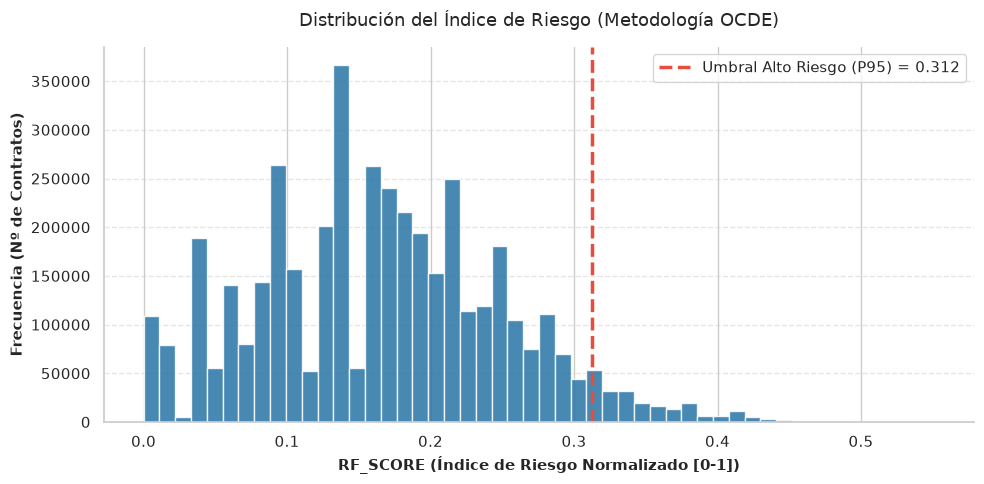

In [15]:
# Análisis exploratorio

# Leo el parquet. Solo cargo las columnas que necesito para el EDA
# (cargar las 69 columnas completas con 4,26M filas se puede quedar sin memoria).
_rf_flags_eda = list(pesos_red_flags.keys())  # 22 red flags binarias
features_pd = pd.read_parquet(path_features, columns=_rf_flags_eda + [
    'RF_SCORE', 'RF_LABEL', 'RF_COUNT',
    'ISO_COUNTRY_CODE', 'CPV_DIVISION', 'YEAR',
    'NUMBER_OFFERS', 'AWARD_VALUE_EURO_FIN_1', 'VALUE_EURO_FIN_1_CN'
])

print(f"Dataset cargado en Pandas: {len(features_pd):,} filas x {len(features_pd.columns)} columnas.")

# Visualización: Distribución del Índice de Riesgo (RF_SCORE)
fig, ax = plt.subplots(figsize=(10, 5))

# Histograma principal
ax.hist(features_pd['RF_SCORE'], bins=50, color='#2874A6', edgecolor='white', alpha=0.85)

# Cálculo y trazado de la línea del Percentil 95
p95_pandas = features_pd['RF_SCORE'].quantile(0.95)
ax.axvline(
    p95_pandas, 
    color='#E74C3C', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'Umbral Alto Riesgo (P95) = {p95_pandas:.3f}'
)

# Etiquetas y título
ax.set_xlabel('RF_SCORE (Índice de Riesgo Normalizado [0-1])', fontsize=11, fontweight='bold')
ax.set_ylabel('Frecuencia (Nº de Contratos)', fontsize=11, fontweight='bold')
ax.set_title('Distribución del Índice de Riesgo (Metodología OCDE)', fontsize=13, pad=15)

# Limpieza visual
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(fontsize=11)
plt.tight_layout()

plt.show()


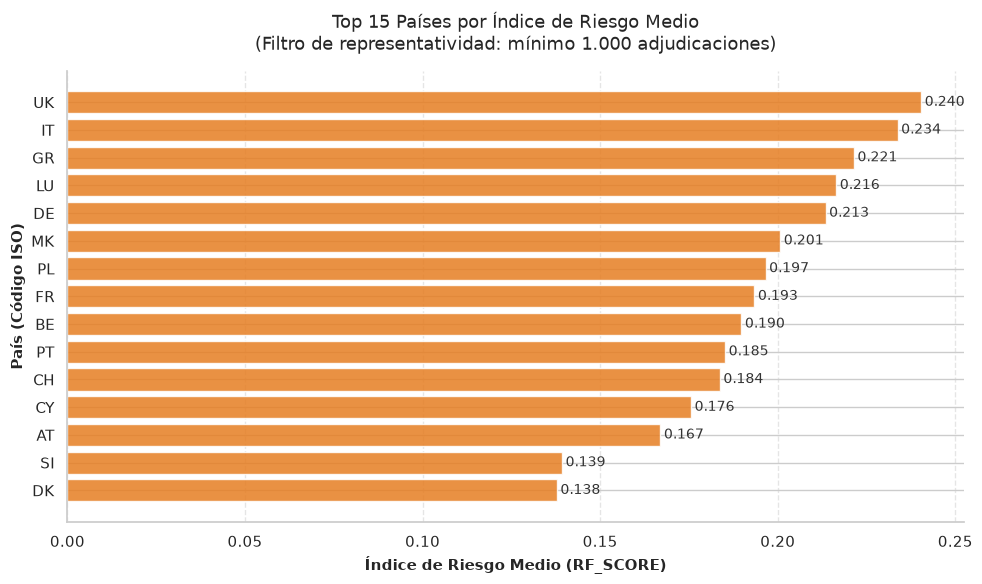

In [16]:
# Visualización: Top 15 Países con mayor Índice de Riesgo Medio

# Media del score y volumen de contratos por país
estadisticas_pais = features_pd.groupby('ISO_COUNTRY_CODE')['RF_SCORE'].agg(['mean', 'count']).reset_index()

# Exijo un mínimo de 1.000 contratos para evitar ruido estadístico (varianza de muestras pequeñas)
top_paises = estadisticas_pais[estadisticas_pais['count'] >= 1000] \
    .sort_values('mean', ascending=False) \
    .head(15)

# Gráfica
fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de barras horizontales
barras = ax.barh(top_paises['ISO_COUNTRY_CODE'], top_paises['mean'], color='#E67E22', edgecolor='white', alpha=0.85)

# Invierto el eje Y para que el país con mayor riesgo aparezca en la parte superior
ax.invert_yaxis()

# Etiquetas y título
ax.set_xlabel('Índice de Riesgo Medio (RF_SCORE)', fontsize=11, fontweight='bold')
ax.set_ylabel('País (Código ISO)', fontsize=11, fontweight='bold')
ax.set_title('Top 15 Países por Índice de Riesgo Medio\n(Filtro de representatividad: mínimo 1.000 adjudicaciones)', fontsize=13, pad=15)

# Limpieza visual y grid
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Añado el valor al lado de cada barra
for barra in barras:
    ancho = barra.get_width()
    ax.text(ancho + 0.001, barra.get_y() + barra.get_height()/2, 
            f'{ancho:.3f}', 
            va='center', ha='left', fontsize=10, color='#333333')

plt.tight_layout()
plt.show()


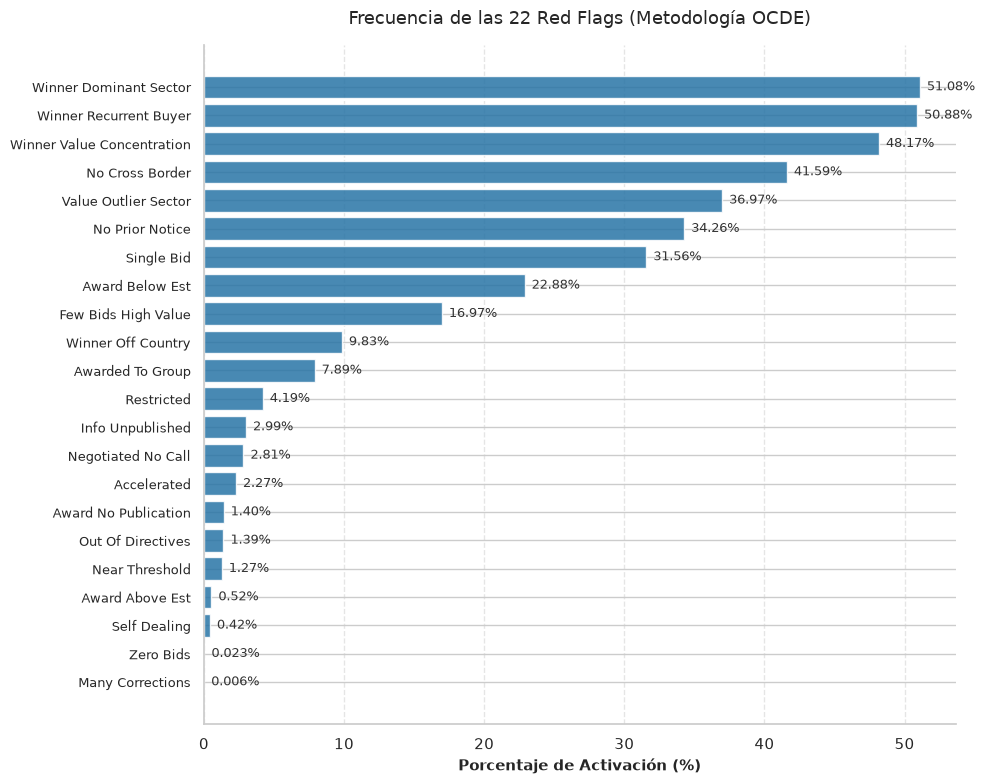

In [17]:
# Visualización: Frecuencia de Activación de las 22 Red Flags

# Columnas de red flags, excluyendo las métricas agregadas
columnas_rf = [c for c in features_pd.columns if c.startswith('RF_') and c not in ('RF_SCORE', 'RF_LABEL', 'RF_COUNT')]

# Porcentaje de activación, ordenado de menor a mayor
frecuencias_rf = (features_pd[columnas_rf].mean() * 100).sort_values(ascending=True)

# Gráfica
fig, ax = plt.subplots(figsize=(10, 8))

# Gráfico de barras horizontales
barras = ax.barh(range(len(frecuencias_rf)), frecuencias_rf.values, color='#2874A6', edgecolor='white', alpha=0.85)

# Configuración del eje Y
ax.set_yticks(range(len(frecuencias_rf)))
# Quito el prefijo 'RF_', cambio guiones por espacios y capitalizo como título para mayor legibilidad
etiquetas_limpias = [nombre.replace('RF_', '').replace('_', ' ').title() for nombre in frecuencias_rf.index]
ax.set_yticklabels(etiquetas_limpias, fontsize=9)

# Etiquetas y título
ax.set_xlabel('Porcentaje de Activación (%)', fontsize=11, fontweight='bold')
ax.set_title('Frecuencia de las 22 Red Flags (Metodología OCDE)', fontsize=13, pad=15)

# Limpieza visual y grid
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Añado el valor exacto al lado de cada barra
for barra in barras:
    ancho = barra.get_width()
    # Si la frecuencia es súper baja, muestro 3 decimales; si no, 2
    formato = f'{ancho:.2f}%' if ancho >= 0.1 else f'{ancho:.3f}%'
    ax.text(ancho + (frecuencias_rf.max() * 0.01), barra.get_y() + barra.get_height()/2, 
            formato, 
            va='center', ha='left', fontsize=9, color='#333333')

plt.tight_layout()
plt.show()


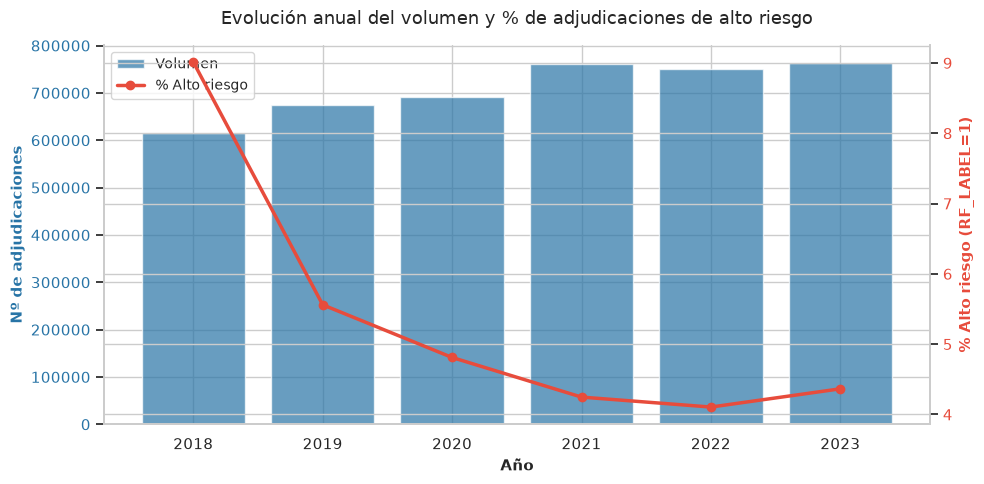

In [18]:
# Evolución anual: volumen de adjudicaciones y porcentaje de alto riesgo
# Quiero ver si el volumen ha crecido y si la proporción de sospechosas cambia con el tiempo

agg_anual = features_pd.groupby('YEAR').agg(
    volumen=('RF_SCORE', 'count'),
    pct_alto_riesgo=('RF_LABEL', 'mean')
).reset_index()
# Convierto a porcentaje
agg_anual['pct_alto_riesgo'] *= 100

fig, ax1 = plt.subplots(figsize=(10, 5))

# Eje izquierdo: volumen de adjudicaciones (barras)
ax1.bar(agg_anual['YEAR'], agg_anual['volumen'], color='#2874A6', alpha=0.7, label='Volumen')
ax1.set_xlabel('Año', fontsize=11, fontweight='bold')
ax1.set_ylabel('Nº de adjudicaciones', fontsize=11, fontweight='bold', color='#2874A6')
ax1.tick_params(axis='y', labelcolor='#2874A6')

# Eje derecho: porcentaje de alto riesgo (línea)
ax2 = ax1.twinx()
ax2.plot(agg_anual['YEAR'], agg_anual['pct_alto_riesgo'], color='#E74C3C', marker='o', linewidth=2.5, label='% Alto riesgo')
ax2.set_ylabel('% Alto riesgo (RF_LABEL=1)', fontsize=11, fontweight='bold', color='#E74C3C')
ax2.tick_params(axis='y', labelcolor='#E74C3C')

ax1.set_title('Evolución anual del volumen y % de adjudicaciones de alto riesgo', fontsize=13, pad=15)
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# Leyenda combinada de los dos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()


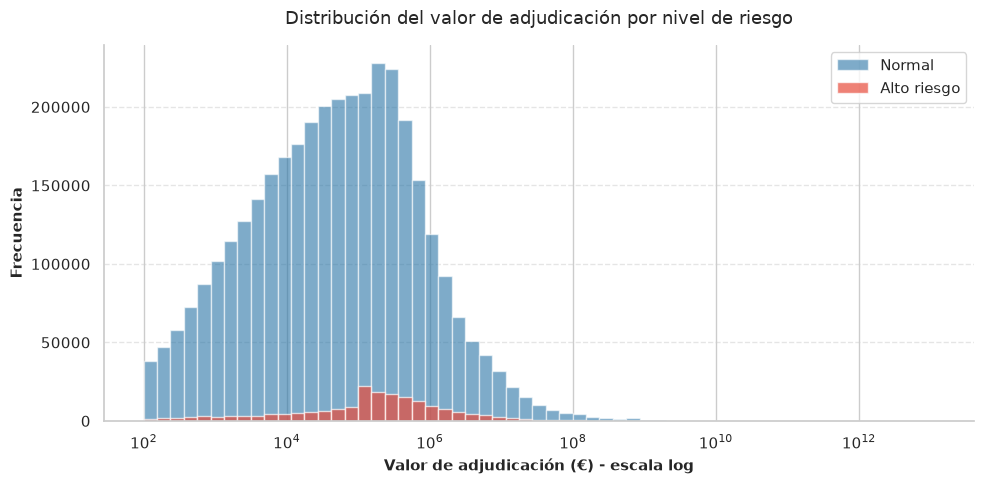

In [19]:
# Distribución del valor de adjudicación (escala logarítmica)
# Los importes están súper sesgados (hay contratos de 100€ y de millones), así que uso log

# Separo alto riesgo vs normal para ver si hay diferencia en los importes
mask_alto = features_pd['RF_LABEL'] == 1
valores_normal = features_pd.loc[~mask_alto, 'AWARD_VALUE_EURO_FIN_1'].dropna()
valores_normal = valores_normal[valores_normal > 0]  # quito ceros y negativos que no tienen sentido
valores_alto = features_pd.loc[mask_alto, 'AWARD_VALUE_EURO_FIN_1'].dropna()
valores_alto = valores_alto[valores_alto > 0]

fig, ax = plt.subplots(figsize=(10, 5))

# Histograma superpuesto con escala log en el eje X
bins = np.logspace(np.log10(100), np.log10(valores_normal.max()), 60)
ax.hist(valores_normal, bins=bins, color='#2874A6', alpha=0.6, label='Normal', edgecolor='white')
ax.hist(valores_alto, bins=bins, color='#E74C3C', alpha=0.7, label='Alto riesgo', edgecolor='white')

ax.set_xscale('log')
ax.set_xlabel('Valor de adjudicación (€) - escala log', fontsize=11, fontweight='bold')
ax.set_ylabel('Frecuencia', fontsize=11, fontweight='bold')
ax.set_title('Distribución del valor de adjudicación por nivel de riesgo', fontsize=13, pad=15)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


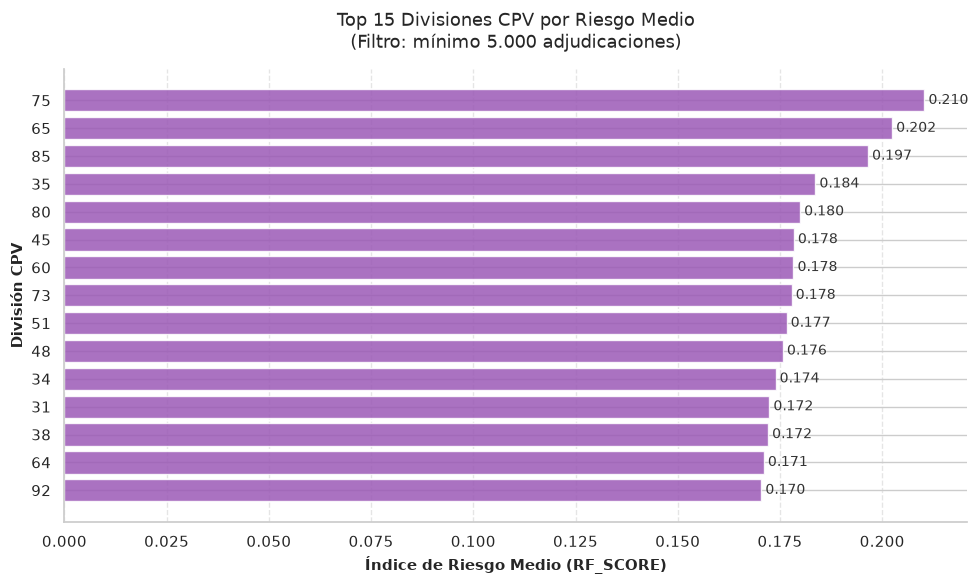

In [20]:
# Top 15 divisiones CPV por riesgo medio
# Igual que hice con los países, filtro por volumen mínimo para que no salgan divisiones raras con 3 contratos

estadisticas_cpv = features_pd.groupby('CPV_DIVISION')['RF_SCORE'].agg(['mean', 'count']).reset_index()
top_cpv = estadisticas_cpv[estadisticas_cpv['count'] >= 5000] \
    .sort_values('mean', ascending=False) \
    .head(15)

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(top_cpv['CPV_DIVISION'].astype(str), top_cpv['mean'], color='#9B59B6', edgecolor='white', alpha=0.85)
ax.invert_yaxis()

ax.set_xlabel('Índice de Riesgo Medio (RF_SCORE)', fontsize=11, fontweight='bold')
ax.set_ylabel('División CPV', fontsize=11, fontweight='bold')
ax.set_title('Top 15 Divisiones CPV por Riesgo Medio\n(Filtro: mínimo 5.000 adjudicaciones)', fontsize=13, pad=15)

ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for barra in barras:
    ancho = barra.get_width()
    ax.text(ancho + 0.001, barra.get_y() + barra.get_height()/2, 
            f'{ancho:.3f}', va='center', ha='left', fontsize=10, color='#333333')

plt.tight_layout()
plt.show()


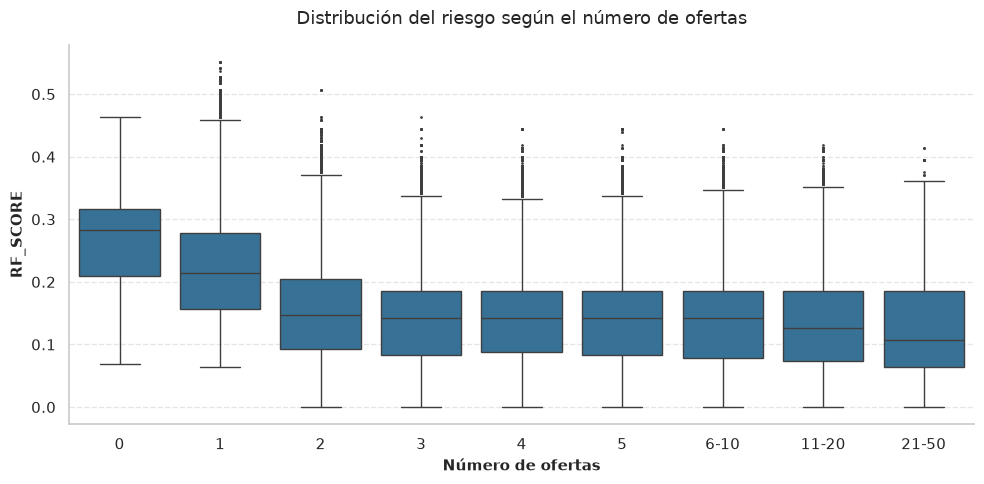

In [21]:
# Riesgo según el número de ofertas
# Agrupo el número de ofertas en bins porque tiene una cola larguísima y si no el boxplot no se lee

# Filtro valores válidos y quito outliers extremos (más de 50 ofertas es rarísimo)
df_offers = features_pd[['NUMBER_OFFERS', 'RF_SCORE']].dropna()
df_offers = df_offers[df_offers['NUMBER_OFFERS'] <= 50]

# Creo bins: 0, 1, 2, 3, 4, 5, 6-10, 11-20, 21-50
bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 10.5, 20.5, 50.5]
labels = ['0', '1', '2', '3', '4', '5', '6-10', '11-20', '21-50']
df_offers['grupo'] = pd.cut(df_offers['NUMBER_OFFERS'], bins=bins, labels=labels)

fig, ax = plt.subplots(figsize=(10, 5))

# Boxplot con seaborn que queda más limpio que matplotlib puro
sns.boxplot(data=df_offers, x='grupo', y='RF_SCORE', ax=ax, 
            color='#2874A6', fliersize=1, linewidth=1)

ax.set_xlabel('Número de ofertas', fontsize=11, fontweight='bold')
ax.set_ylabel('RF_SCORE', fontsize=11, fontweight='bold')
ax.set_title('Distribución del riesgo según el número de ofertas', fontsize=13, pad=15)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


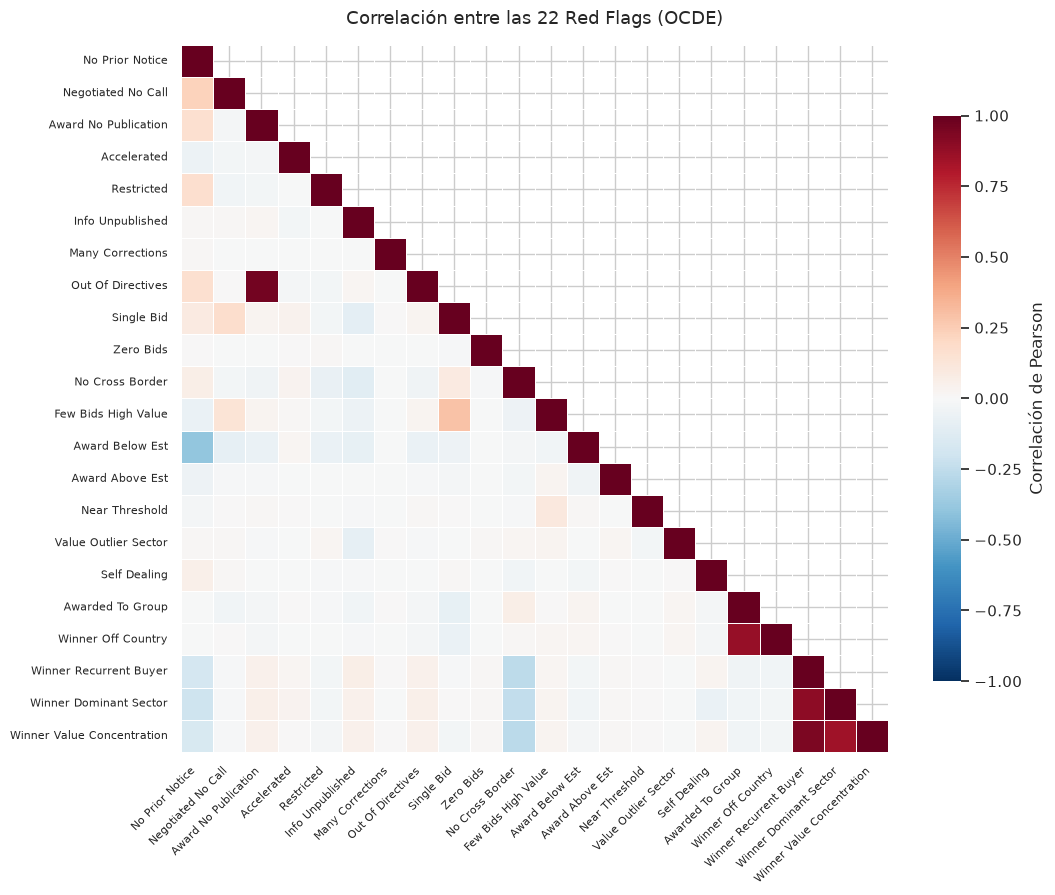

In [22]:
# Mapa de calor de correlación entre las 22 red flags
# Quiero ver si hay banderas que se activan juntas (colinealidad), lo cual tiene sentido
# porque algunas son parecidas conceptualmente

# Matriz de correlación solo de las 22 red flags binarias
matriz_corr = features_pd[columnas_rf].corr()

fig, ax = plt.subplots(figsize=(11, 9))

# Enmascaro la mitad superior para no duplicar info (la matriz es simétrica)
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)

sns.heatmap(matriz_corr, mask=mascara, ax=ax, 
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=False, square=True, linewidths=0.5,
            cbar_kws={'label': 'Correlación de Pearson', 'shrink': 0.8})

# Etiquetas legibles en los ejes (quito el prefijo RF_)
etiquetas = [c.replace('RF_', '').replace('_', ' ').title() for c in columnas_rf]
ax.set_xticklabels(etiquetas, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)

ax.set_title('Correlación entre las 22 Red Flags (OCDE)', fontsize=13, pad=15)

plt.tight_layout()
plt.show()


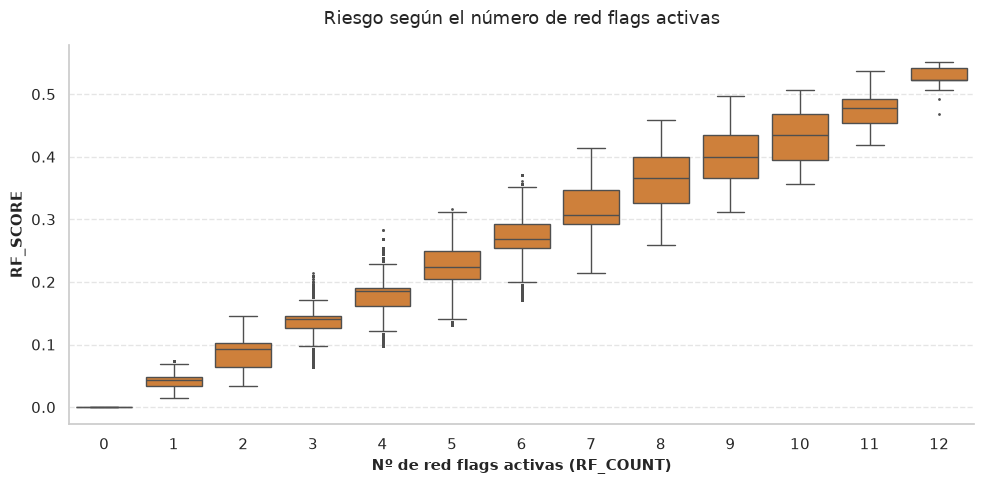

In [23]:
# Riesgo según el número de banderas activas (RF_COUNT)
# Tiene que haber relación positiva (más banderas = más riesgo), pero quiero ver la forma

df_count = features_pd[['RF_COUNT', 'RF_SCORE']].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(data=df_count, x='RF_COUNT', y='RF_SCORE', ax=ax,
            color='#E67E22', fliersize=1, linewidth=1)

ax.set_xlabel('Nº de red flags activas (RF_COUNT)', fontsize=11, fontweight='bold')
ax.set_ylabel('RF_SCORE', fontsize=11, fontweight='bold')
ax.set_title('Riesgo según el número de red flags activas', fontsize=13, pad=15)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


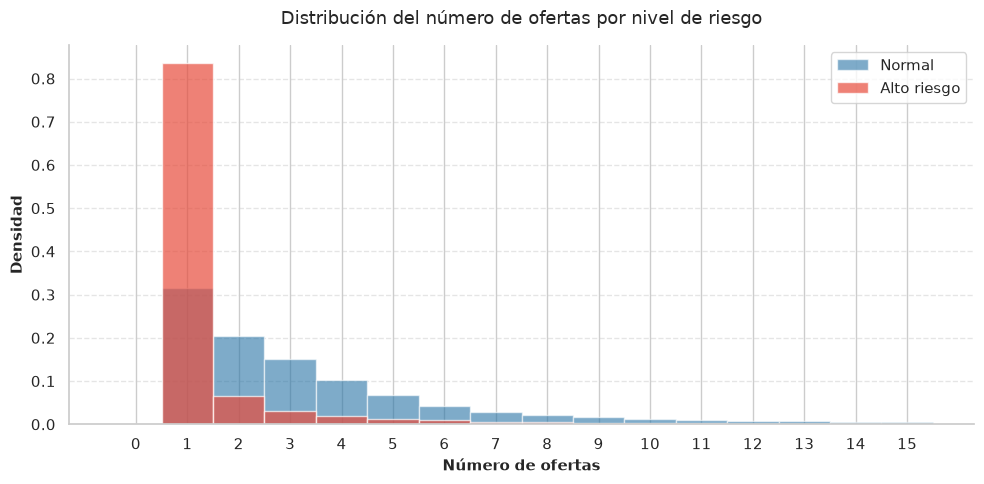

In [24]:
# Distribución del número de ofertas: alto riesgo vs normal
# La hipótesis es que las sospechosas tienen menos ofertas (competencia limitada)

df_noffers = features_pd[['NUMBER_OFFERS', 'RF_LABEL']].dropna()
# Limito a 15 ofertas para que el gráfico sea legible (el 99% está por debajo)
df_noffers = df_noffers[df_noffers['NUMBER_OFFERS'] <= 15]

normal = df_noffers[df_noffers['RF_LABEL'] == 0]['NUMBER_OFFERS']
alto = df_noffers[df_noffers['RF_LABEL'] == 1]['NUMBER_OFFERS']

fig, ax = plt.subplots(figsize=(10, 5))

# Histograma normalizado (density=True) para comparar proporciones
# Hay muchos más normales que sospechosos, así que si no normalizo no se ve nada
bins = np.arange(-0.5, 16.5, 1)
ax.hist(normal, bins=bins, density=True, color='#2874A6', alpha=0.6, label='Normal', edgecolor='white')
ax.hist(alto, bins=bins, density=True, color='#E74C3C', alpha=0.7, label='Alto riesgo', edgecolor='white')

ax.set_xlabel('Número de ofertas', fontsize=11, fontweight='bold')
ax.set_ylabel('Densidad', fontsize=11, fontweight='bold')
ax.set_title('Distribución del número de ofertas por nivel de riesgo', fontsize=13, pad=15)

ax.set_xticks(range(0, 16))
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


## Fase 4 — Modelado

Estrategia de evaluación con cuatro aproximaciones complementarias:
- **Supervisados (calibración de frontera)**: Random Forest distribuido (`pyspark.ml`) sobre el tablón completo de 4,26M registros y red neuronal densa (`Keras`) para evaluar no-linealidades sobre la pseudo-etiqueta.
- **No supervisados (detección de anomalías)**: Isolation Forest (`scikit-learn`) como línea base rápida sobre submuestra y Autoencoder (`Keras`) entrenado exclusivamente con la clase mayoritaria para identificar patrones fuera de las reglas OCDE.

**Espacio de características (32 dimensiones)**: 22 *red flags* binarias + 5 continuas estandarizadas + 5 máscaras booleanas de ausencia (cruciales para no distorsionar variables con alto volumen de nulos, como el 69% de `RATIO_AWARD_EST`).

**Entorno de ejecución**: Spark MLlib gestiona el procesamiento distribuido en clúster; Keras opera en memoria local sobre el nodo conductor (48 GB RAM) para disponer de capas de regularización (`BatchNormalization`, `Dropout`) y parada temprana (`EarlyStopping`), ausentes en MLlib. El desbalanceo de clases (5,23% positivos) se ajusta mediante `class_weight`.


In [25]:
# Preparacion de datos para modelado predictivo
# Uso el tablon COMPLETO de 4,26M filas (sin muestreo).
# Cargo solo las columnas que necesito (27 features + label)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Columnas necesarias para modelado (27 features + label)
cols_modelo = list(columnas_features_ocde) + ['RF_LABEL']
features_pd = pd.read_parquet(path_features, columns=cols_modelo)
print(f"Tablon de modelado: {len(features_pd):,} filas x {len(features_pd.columns)} columnas")
print(f"  -> RF_LABEL=1 (Alto Riesgo): {(features_pd['RF_LABEL']==1).sum():,} ({features_pd['RF_LABEL'].mean()*100:.2f}%)")

# Particion Train/Test (80/20) estratificada por RF_LABEL
train_df, test_df = train_test_split(
    features_pd,
    test_size=0.2,
    stratify=features_pd['RF_LABEL'],
    random_state=0
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"  -> Train: {len(train_df):,} | Test: {len(test_df):,}")


Tablon de modelado: 4,256,060 filas x 28 columnas
  -> RF_LABEL=1 (Alto Riesgo): 222,676 (5.23%)


  -> Train: 3,404,848 | Test: 851,212


In [26]:
# --- Preprocesado de features para Deep Learning ---------------------------
# Las 27 features del tablon (22 binarias + 5 continuas) no entran tal cual
# en la red: las continuas se escalan con StandardScaler ajustado en train
# (antifuga), los NaN se imputan a 0 y se añade una mascara binaria para
# senalizar el valor ausente. Resultado: 32 dimensiones de entrada.

# Lista canónica de 27 features (22 binarias + 5 continuas), ordenada.
FEATURE_COLUMNS = list(columnas_features_ocde)  # definida en Fase 2 (cell 10)
N_BINARY = sum(1 for c in FEATURE_COLUMNS if c.startswith('RF_'))
N_CONTINUOUS = len(FEATURE_COLUMNS) - N_BINARY
INPUT_DIM = N_BINARY + N_CONTINUOUS + N_CONTINUOUS  # 22 + 5 + 5 = 32

X_train_raw = train_df[FEATURE_COLUMNS].to_numpy()
y_train = train_df['RF_LABEL'].to_numpy().astype(np.float32)
X_test_raw = test_df[FEATURE_COLUMNS].to_numpy()
y_test = test_df['RF_LABEL'].to_numpy().astype(np.float32)

# Escalado de continuas (fit en train, antifuga de informacion)
cont_train = X_train_raw[:, N_BINARY:]
mean_train = np.nanmean(cont_train, axis=0)
mean_train = np.where(np.isnan(mean_train), 0.0, mean_train)
cont_train_filled = np.where(np.isnan(cont_train), mean_train, cont_train)
scaler = StandardScaler().fit(cont_train_filled)

def scale_with_nans(arr):
    """Escala las continuas preservando NaN para la mascara de nulo."""
    bin_part = arr[:, :N_BINARY]
    cont_part = arr[:, N_BINARY:]
    scaled = scaler.transform(np.nan_to_num(cont_part, nan=mean_train))
    scaled = np.where(np.isnan(cont_part), np.nan, scaled)
    return np.concatenate([bin_part, scaled], axis=1)

def make_input_matrix(arr):
    # Junto las binarias, las continuas con NaN->0, y una columna extra
    # que vale 1 donde habia NaN y 0 donde no. Asi la red sabe si un 0
    # es de verdad o es que faltaba el dato.
    bin_part = arr[:, :N_BINARY].astype(np.float32)
    cont_part = arr[:, N_BINARY:].astype(np.float32)
    nan_mask = np.isnan(cont_part).astype(np.float32)
    cont_imputed = np.nan_to_num(cont_part, nan=0.0)
    return np.concatenate([bin_part, cont_imputed, nan_mask], axis=1).astype(np.float32)

X_train = make_input_matrix(scale_with_nans(X_train_raw))
X_test = make_input_matrix(scale_with_nans(X_test_raw))
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"  Binarias: {N_BINARY} | Continuas: {N_CONTINUOUS} | Mascaras: {N_CONTINUOUS} => {INPUT_DIM} dims")


X_train: (3404848, 32) | X_test: (851212, 32)
  Binarias: 22 | Continuas: 5 | Mascaras: 5 => 32 dims


### 4.1 Random Forest distribuido (Spark MLlib)

Entrenamiento de una línea base supervisada en clúster (`pyspark.ml`) sobre el tablón consolidado completo (4,26 millones de registros), procesando el Parquet como Spark DataFrame nativo. 

**Objetivo y justificación**:
- **Escalabilidad distribuida**: Establece el rendimiento de referencia sobre infraestructura Big Data frente a los modelos entrenados en memoria local (`Keras`/`scikit-learn`).
- **Interpretabilidad nativa**: Proporciona el vector de importancia relativa de variables (`featureImportances`) para contrastar con la atribución de SHAP en las redes densas.
- **Tolerancia estructural**: Al basarse en ensamblados de árboles, no requiere estandarización de variables continuas ni incorporación de máscaras booleanas.

**Configuración del pipeline**:
El flujo ensambla las 27 características primarias (22 binarias y 5 continuas con imputación a cero previa al vectorizado, requerida por MLlib) mediante `VectorAssembler`. La selección de hiperparámetros se realiza con `TrainValidationSplit` (evaluando `numTrees` $\in \{50, 100\}$ y `maxDepth` $\in \{6, 8\}$) y `BinaryClassificationEvaluator` optimizando el área bajo la curva ROC.

In [27]:
# --- Random Forest distribuido con Spark MLlib -------------------------
# Entreno un RandomForest con el motor distribuido de Spark, leyendo
# el parquet completo (4,26M filas) directamente como Spark DataFrame.
# Uso Pipeline + VectorAssembler + TrainValidationSplit para tunear
# numTrees y maxDepth.
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.tuning import TrainValidationSplit, ParamGridBuilder
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql.functions import udf
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from pyspark.sql.types import DoubleType
import time as _time

# Cargo el parquet completo en Spark
df_spark = spark.read.parquet(path_features)
print(f"Spark RF - tablon completo: {df_spark.count():,} filas")

# MLlib no acepta NaN en las features, asi que imputo a 0 las continuas
for col_name in FEATURE_COLUMNS:
    if not col_name.startswith('RF_'):
        df_spark = df_spark.withColumn(col_name, F.coalesce(F.col(col_name), F.lit(0.0)))

# La etiqueta tiene que ser double para MLlib
df_spark = df_spark.withColumn('label', F.col('RF_LABEL').cast('double'))

# Split train/test 80/20 con semilla fija
train_spark, test_spark = df_spark.randomSplit([0.8, 0.2], seed=0)
train_spark.cache()
print(f"Spark RF - Train: {train_spark.count():,} | Test: {test_spark.count():,}")

# Monto el pipeline: VectorAssembler junta las 27 features en un vector
# y luego el RandomForest clasifica
assembler = VectorAssembler(
    inputCols=list(FEATURE_COLUMNS),
    outputCol='features',
    handleInvalid='keep'
)

rf = RandomForestClassifier(
    featuresCol='features',
    labelCol='label',
    seed=0,
    numTrees=50,
    maxDepth=8,
)

pipeline_rf = Pipeline(stages=[assembler, rf])

# Pruebo 4 combinaciones de hiperparametros
paramGrid = ParamGridBuilder() \
    .addGrid(rf.numTrees, [50, 100]) \
    .addGrid(rf.maxDepth, [6, 8]) \
    .build()

evaluator = BinaryClassificationEvaluator(
    labelCol='label',
    rawPredictionCol='rawPrediction',
    metricName='areaUnderROC'
)

tvs = TrainValidationSplit(
    estimator=pipeline_rf,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator,
    seed=0,
    parallelism=2,
)

print('Entrenando RandomForest distribuido sobre 4,26M filas (4 combos)...')
t0 = _time.time()
tvs_model = tvs.fit(train_spark)
t_rf = _time.time() - t0
print(f'TrainValidationSplit completado en {t_rf:.1f}s')

# Veo que configuracion ha ganado
best_pipeline = tvs_model.bestModel
rf_model = best_pipeline.stages[-1]
print(f'Mejor config: numTrees={rf_model.getNumTrees}, maxDepth={rf_model.getOrDefault("maxDepth")}')

# Predigo sobre test y extraigo la probabilidad de la clase 1
pred_rf = tvs_model.transform(test_spark)

extract_prob = udf(lambda v: float(v[1]) if v is not None and len(v) > 1 else 0.0, DoubleType())
pred_rf = pred_rf.withColumn('score', extract_prob(F.col('probability')))

# Paso a Pandas para calcular metricas con sklearn
pred_pd = pred_rf.select('score', 'label').toPandas()
s_rf = pred_pd['score'].values.astype(np.float32)
y_rf = pred_pd['label'].values.astype(int)

auroc_rf = roc_auc_score(y_rf, s_rf)
auprc_rf = average_precision_score(y_rf, s_rf)

# Busco el F1 maximo probando varios umbrales
thrs_rf = np.quantile(s_rf, np.linspace(0.5, 0.99, 30))
f1_rf = 0.0
for t in thrs_rf:
    f1_t = f1_score(y_rf, (s_rf >= t).astype(int))
    if f1_t > f1_rf:
        f1_rf = float(f1_t)
print(f'\nRandomForest (MLlib, 4,26M): AUROC={auroc_rf:.4f} AUPRC={auprc_rf:.4f} F1={f1_rf:.4f} ({t_rf:.1f}s)')

# Feature importance del RF distribuido
rf_importances = rf_model.featureImportances.toArray()
rf_feat_imp = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance': rf_importances
}).sort_values('importance', ascending=False)
print('\nTop 10 features (RF importance):')
print(rf_feat_imp.head(10).to_string(index=False))

# Guardo el pipeline entrenado
os.makedirs(str(PROJ_ROOT / 'models'), exist_ok=True)
tvs_model.write().overwrite().save(str(PROJ_ROOT / 'models' / 'spark_rf_pipeline'))
print(f'\nPipeline RF guardado en models/spark_rf_pipeline/')

# Paro Spark para liberar memoria antes de entrenar Keras
spark.stop()
print('Spark detenido.')



Spark RF - tablon completo: 4,256,060 filas


Spark RF - Train: 3,404,575 | Test: 851,485
Entrenando RandomForest distribuido sobre 4,26M filas (4 combos)...


26/09/09 20:06:29 WARN DAGScheduler: Broadcasting large task binary with size 1054.7 KiB


26/09/09 20:06:35 WARN DAGScheduler: Broadcasting large task binary with size 1745.3 KiB


26/09/09 20:06:43 WARN DAGScheduler: Broadcasting large task binary with size 1142.4 KiB


26/09/09 20:07:24 WARN DAGScheduler: Broadcasting large task binary with size 1099.6 KiB


... (8 outputs left out)

26/09/09 20:10:01 WARN DAGScheduler: Broadcasting large task binary with size 2043.3 KiB



RandomForest (MLlib, 4,26M): AUROC=0.9979 AUPRC=0.9742 F1=0.8983 (254.9s)

Top 10 features (RF importance):
                      feature  importance
           RF_NO_PRIOR_NOTICE    0.148474
         RF_OUT_OF_DIRECTIVES    0.121255
                RF_SINGLE_BID    0.120452
        RF_NEGOTIATED_NO_CALL    0.118762
      RF_AWARD_NO_PUBLICATION    0.094728
       RF_FEW_BIDS_HIGH_VALUE    0.068751
    RF_WINNER_RECURRENT_BUYER    0.055193
RF_WINNER_VALUE_CONCENTRATION    0.047542
     WINNER_VALUE_SHARE_BUYER    0.039497
           WINNER_SHARE_BUYER    0.029854



Pipeline RF guardado en models/spark_rf_pipeline/


Spark detenido.


### 4.2 Isolation Forest (baseline)

In [28]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
import time

t0 = time.time()
X_normal = X_train[y_train == 0]
rng = np.random.default_rng(0)
idx = rng.choice(len(X_normal), size=min(200_000, len(X_normal)), replace=False)
if_model = IsolationForest(n_estimators=200, contamination='auto', random_state=0, n_jobs=-1)
if_model.fit(X_normal[idx])
t_if = time.time() - t0

# Score: decision_function negado y normalizado [0,1]
raw_if = -if_model.decision_function(X_test)
lo, hi = np.quantile(raw_if, 0.01), np.quantile(raw_if, 0.99)
s_if = np.clip((raw_if - lo) / (hi - lo), 0, 1)

auroc_if = roc_auc_score(y_test, s_if)
auprc_if = average_precision_score(y_test, s_if)
print(f"Isolation Forest: AUROC={auroc_if:.4f} AUPRC={auprc_if:.4f} tiempo={t_if:.1f}s")



Isolation Forest: AUROC=0.8205 AUPRC=0.1894 tiempo=0.3s


### 4.3 Autoencoder (no supervisado, Keras)

In [29]:
# --- Autoencoder (no supervisado, Keras) ---------------------------------
# Entreno SOLO con la clase mayoritaria (RF_LABEL=0) para que aprenda
# el patron de las adjudicaciones "normales". Las anomalas (fraude
# potencial) se reconstruyen con mayor error de MSE, que uso como
# score de anomalia.
from tensorflow import keras
from tensorflow.keras import layers

# Semilla TF: inicializaciones, shuffle y dropout reproducibles (semilla 0 global)
keras.utils.set_random_seed(0)

INPUT_DIM = X_train.shape[1]  # 32

# Arquitectura: 32 -> 24 -> 4 (bottleneck) -> 24 -> 32
autoencoder = keras.Sequential([
    keras.Input(shape=(INPUT_DIM,), name='ae_input'),
    layers.Dense(24, activation='relu', name='enc_1'),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(4, activation='relu', name='bottleneck'),
    layers.Dense(24, activation='relu', name='dec_1'),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(INPUT_DIM, name='reconstruction'),
], name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

# Entrenamiento: x como entrada y como target (autoasociacion)
X_normal_train = X_train[y_train == 0]
print(f"\nTrain normal: {len(X_normal_train):,} filas (clase mayoritaria)")

callbacks_ae = [
    keras.callbacks.EarlyStopping(monitor='loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=3, min_lr=1e-6),
]

t0 = time.time()
autoencoder.fit(
    X_normal_train, X_normal_train,
    epochs=15, batch_size=2048, shuffle=True, verbose=2,
    callbacks=callbacks_ae,
)
t_ae = time.time() - t0

# Score: error de reconstruccion MSE por muestra, normalizado a [0,1]
X_test_pred = autoencoder.predict(X_test, verbose=2)
err = np.mean((X_test - X_test_pred) ** 2, axis=1)
lo, hi = np.quantile(err, 0.01), np.quantile(err, 0.99)
s_ae = np.clip((err - lo) / (hi - lo), 0.0, 1.0)

auroc_ae = roc_auc_score(y_test, s_ae)
auprc_ae = average_precision_score(y_test, s_ae)
thrs = np.quantile(s_ae, np.linspace(0.5, 0.99, 30))
f1_ae = 0.0
for t in thrs:
    f1_t = f1_score(y_test, (s_ae >= t).astype(int))
    if f1_t > f1_ae:
        f1_ae = float(f1_t)
print(f"\nAutoencoder: AUROC={auroc_ae:.4f} AUPRC={auprc_ae:.4f} F1={f1_ae:.4f} ({t_ae:.1f}s)")


I0000 00:00:1788977421.438948   31206 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ enc_1 (Dense)                   │ (None, 24)             │           792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 24)             │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 4)              │           100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 24)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24)             │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 32)             │           800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,004 (7.83 KB)

 Trainable params: 1,908 (7.45 KB)

 Non-trainable params: 96 (384.00 B)

... (29 outputs left out)

Epoch 15/15


1576/1576 - 1s - 856us/step - loss: 0.0392 - learning_rate: 5.0000e-04


26601/26601 - 4s - 142us/step



Autoencoder: AUROC=0.8566 AUPRC=0.2010 F1=0.3171 (21.1s)


### 4.4 Red neuronal densa (supervisión débil, Keras)

Clasificador binario orientado a suavizar la frontera de decisión rígida del percentil 95, estimando una distribución continua de probabilidad a partir de interacciones no lineales entre las 32 variables de entrada.

- **Arquitectura**: Red secuencial feedforward (32 → 64 → 32 → 16 → 1) con activación sigmoide en la salida (4.961 parámetros entrenables).
- **Regularización y optimización**: Capas intercaladas de `BatchNormalization` y `Dropout(0.2)` optimizadas mediante `binary_crossentropy` y Adam, con parada temprana (`patience = 5`) y reducción de tasa de aprendizaje ante estancamiento.
- **Manejo de desbalance**: Ajuste de penalización en la función de pérdida mediante `class_weight` inverso a la prevalencia de positivos (5,23%).

In [30]:
# --- DNN clasificador (supervisado debil, Keras) -------------------------
from tensorflow.keras import layers

# Semilla TF: inicializaciones, shuffle y dropout reproducibles (semilla 0 global)
keras.utils.set_random_seed(0)

# Arquitectura funcional: 32 -> 64 -> 32 -> 16 -> 1 (sigmoid)
inputs = keras.Input(shape=(INPUT_DIM,), name='dnn_input')
x = layers.Dense(64, activation='relu', name='dense_1')(inputs)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu', name='dense_2')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(16, activation='relu', name='dense_3')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

dnn = keras.Model(inputs, outputs, name='dnn_classifier')
dnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(name='auroc')],
)
dnn.summary()

# Ponderacion de clases: la pseudo-etiqueta tiene 5,23% positivos.
n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
pos_weight = n_neg / max(n_pos, 1)
class_weights = {0: 1.0, 1: pos_weight}
print(f"\nDNN: pos={n_pos:,} neg={n_neg:,} class_weight[1]={pos_weight:.2f}")

callbacks_dnn = [
    keras.callbacks.EarlyStopping(monitor='loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=3, min_lr=1e-6),
]

t0 = time.time()
dnn.fit(
    X_train, y_train,
    epochs=15, batch_size=2048, shuffle=True, verbose=2,
    class_weight=class_weights,
    callbacks=callbacks_dnn,
)
t_dnn = time.time() - t0

# Score: probabilidad de la clase positiva (sigmoid)
s_dnn = dnn.predict(X_test, verbose=0, batch_size=4096).flatten()

auroc_dnn = roc_auc_score(y_test, s_dnn)
auprc_dnn = average_precision_score(y_test, s_dnn)
thrs = np.quantile(s_dnn, np.linspace(0.5, 0.99, 30))
f1_dnn = 0.0
for t in thrs:
    f1_t = f1_score(y_test, (s_dnn >= t).astype(int))
    if f1_t > f1_dnn:
        f1_dnn = float(f1_t)
print(f"\nDNN: AUROC={auroc_dnn:.4f} AUPRC={auprc_dnn:.4f} F1={f1_dnn:.4f} ({t_dnn:.1f}s)")


Model: "dnn_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dnn_input (InputLayer)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,185 (20.25 KB)

 Trainable params: 4,961 (19.38 KB)

 Non-trainable params: 224 (896.00 B)


DNN: pos=178,141 neg=3,226,707 class_weight[1]=18.11


... (27 outputs left out)

1663/1663 - 2s - 1ms/step - auroc: 1.0000 - loss: 0.0015 - learning_rate: 5.0000e-04


Epoch 15/15


1663/1663 - 2s - 1ms/step - auroc: 1.0000 - loss: 0.0011 - learning_rate: 5.0000e-04



DNN: AUROC=1.0000 AUPRC=1.0000 F1=0.9259 (32.2s)


### 4.5 Comparativa de los 4 modelos

In [31]:
# F1 al umbral optimo
def best_f1(y_true, scores):
    thresholds = np.quantile(scores, np.linspace(0.5, 0.99, 30))
    best, thr = 0, 0.5
    for t in thresholds:
        f1 = f1_score(y_true, (scores >= t).astype(int), zero_division=0)
        if f1 > best:
            best, thr = float(f1), float(t)
    return best, thr

f1_rf, _ = best_f1(y_rf, s_rf)
f1_if, _ = best_f1(y_test, s_if)
f1_ae, _ = best_f1(y_test, s_ae)
f1_dnn, _ = best_f1(y_test, s_dnn)

# Precision@1%: de las predicciones con mayor score, que porcentaje son fraude
order_rf = np.argsort(-s_rf)
p1_rf = y_rf[order_rf[:len(y_rf)//100]].mean()
order_if = np.argsort(-s_if)
p1_if = y_test[order_if[:len(y_test)//100]].mean()
order_ae = np.argsort(-s_ae)
p1_ae = y_test[order_ae[:len(y_test)//100]].mean()
order_dnn = np.argsort(-s_dnn)
p1_dnn = y_test[order_dnn[:len(y_test)//100]].mean()

comparativa = pd.DataFrame({
    'modelo': ['RF (Spark MLlib)', 'Isolation Forest', 'Autoencoder', 'DNN (Keras)'],
    'tipo': ['Supervisado distribuido', 'Baseline no supervisado', 'No supervisado', 'Supervisado debil'],
    'framework': ['pyspark.ml', 'sklearn', 'Keras', 'Keras'],
    'AUROC': [auroc_rf, auroc_if, auroc_ae, auroc_dnn],
    'AUPRC': [auprc_rf, auprc_if, auprc_ae, auprc_dnn],
    'F1': [f1_rf, f1_if, f1_ae, f1_dnn],
    'P@1%': [p1_rf, p1_if, p1_ae, p1_dnn],
    'tiempo_s': [t_rf, t_if, t_ae, t_dnn],
})
display(comparativa)
print(f"\nMejor modelo por AUPRC: {comparativa.loc[comparativa['AUPRC'].idxmax(), 'modelo']}")

,modelo,tipo,framework,AUROC,AUPRC,F1,P@1%,tiempo_s
0,RF (Spark MLlib),Supervisado distribuido,pyspark.ml,0.997880,0.974156,0.898260,1.000000,254.864990
1,Isolation Forest,Baseline no supervisado,sklearn,0.820479,0.189430,0.261728,0.340696,0.319065
2,Autoencoder,No supervisado,Keras,0.856639,0.200956,0.317099,0.272909,21.061239
3,DNN (Keras),Supervisado debil,Keras,1.000000,1.000000,0.925932,1.000000,32.210509



Mejor modelo por AUPRC: DNN (Keras)


**Análisis comparativo de rendimiento**

- **Modelos supervisados (acoplamiento estructural)**: Tanto la DNN (AUROC 1,0000, AUPRC 1,0000) como el Random Forest distribuido de Spark (AUROC 0,9979, AUPRC 0,9742) exhiben un desempeño casi perfecto debido a la relación determinista entre las 22 *red flags* de entrada y la construcción de `RF_LABEL` (corte en P95 de `RF_SCORE`). No reflejan una detección infalible de fraude real, sino la aproximación fidedigna de la regla subyacente mediante combinaciones continuas (red neuronal) o cortes ortogonales (árboles). La coincidencia entre las variables dominantes del Random Forest y la atribución por SHAP en la DNN confirma que la frontera aprendida es consistente entre paradigmas.
- **Modelos no supervisados (detección fuera de distribución)**: El Autoencoder (AUROC 0,8566, AUPRC 0,2010) supera al Isolation Forest (AUROC 0,8205, AUPRC 0,1894) al capturar interacciones latentes complejas en su espacio comprimido. Al no estar condicionados por la pseudo-etiqueta, ambos modelos aportan valor operativo identificando anomalías contractuales no tipificadas por el catálogo de la OCDE.
- **Criterio de arquitectura de software**: Se mantiene una separación funcional estricta: Spark gestiona la ingesta masiva, el *feature engineering* distribuido y el *baseline* en clúster; Keras asume el modelado profundo en memoria local para incorporar capas de regularización (`BatchNormalization`, `Dropout`) y control de convergencia (`EarlyStopping`), ausentes en el catálogo de MLlib.

### Persistencia de artefactos

Exportación a `models/` de los modelos entrenados (`.keras`), el objeto de estandarización (`StandardScaler`), el estimador de `scikit-learn` (`.joblib`) y el *pipeline* serializado de Spark MLlib para su integración en el módulo de inferencia.


## Fase 4.6 — Validación empírica: mitigación de circularidad y representaciones de entidad

El rendimiento cuasi perfecto de la DNN (AUROC 1,0000) y del Random Forest (AUROC 0,9979) deriva del acoplamiento determinista entre las 22 *red flags* de entrada y la definición de `RF_LABEL` (umbral P95 sobre su combinación lineal ponderada). Bajo este diseño, los modelos supervisados optimizan la reconstrucción de la regla manual, sin demostrar de forma concluyente la extracción de señal de riesgo sobre datos primarios.

Para verificar si las arquitecturas profundas son capaces de aprender patrones latentes sin intermediación de las reglas predefinidas, se diseñan tres configuraciones experimentales prescindiendo de las 22 *red flags* en el espacio de entrada:

- **Experimento A (Variables numéricas continuas)**: Espacio de 20 dimensiones compuesto exclusivamente por los registros cuantitativos brutos de los que derivan las alertas (concurrencia, ofertas extranjeras, plazos, importes licitados/adjudicados, ratio presupuestario y desviaciones sectoriales) junto con sus máscaras de ausencia. Evalúa la capacidad predictiva de las magnitudes contractuales.
- **Experimento B (Variables continuas + *Entity Embeddings*)**: Incorpora al conjunto A representaciones densas aprendidas para variables de alta cardinalidad (comprador, adjudicatario, división CPV, países de origen y tipología de procedimiento). Contrasta la hipótesis de que la identidad de los operadores y su recurrencia histórica aportan señal complementaria a las cifras del contrato.
- **Solo *Entity Embeddings***: Modelo entrenado únicamente con los vectores densos de entidad para aislar la capacidad discriminante de la red de actores respecto a los importes y características de la licitación.

In [32]:
# Cargo del parquet las variables crudas y categoricas (no las red flags)
# para los experimentos de validacion. Son las columnas de las que salen
# las red flags, mas los identificadores de las entidades.

RAW_COLUMNS = [
    'NUMBER_OFFERS', 'NUMBER_TENDERS_OTHER_EU', 'NUMBER_TENDERS_NON_EU',
    'CORRECTIONS', 'AWARD_VALUE_EURO_FIN_1', 'VALUE_EURO_FIN_1_CN',
    'LOG_AWARD_VALUE', 'MEDIAN_LOG_VALUE_SECTOR', 'LOTS_NUMBER',
    'DURATION_M_CN', 'HAS_CN',
    'RATIO_AWARD_EST', 'VALUE_DEV_SECTOR',
    'WINNER_SHARE_BUYER', 'WINNER_SHARE_SECTOR', 'WINNER_VALUE_SHARE_BUYER',
]

CAT_COLUMNS = [
    'CAE_NATIONALID', 'WIN_NATIONALID', 'CPV',
    'WIN_COUNTRY_CODE', 'ISO_COUNTRY_CODE', 'TOP_TYPE',
]

df_validacion = pd.read_parquet(path_features, columns=RAW_COLUMNS + CAT_COLUMNS + ['RF_LABEL'])
print(f"Tablon de validacion: {len(df_validacion):,} filas x {len(df_validacion.columns)} columnas")


Tablon de validacion: 4,256,060 filas x 23 columnas


In [33]:
# Limpieza de las categoricas: el pais del ganador trae valores sucios
# (ej. 'PL---PL' o nombres de ciudades), y el tipo de procedimiento tambien.
# Me quedo con los codigos validos y mando el resto a 'OTHER'.

VALID_TOP_TYPE = {'OPE', 'NIC', 'RES', 'NOC', 'AWP', 'NIP', 'NOP', 'COD', 'INP'}

def limpiar_pais(s):
    if isinstance(s, str) and len(s) == 2 and s.isalpha():
        return s.upper()
    return 'OTHER'

def limpiar_tipo(s):
    if isinstance(s, str) and s.strip() in VALID_TOP_TYPE:
        return s.strip()
    return 'OTHER'

df_validacion['WIN_COUNTRY_CODE'] = df_validacion['WIN_COUNTRY_CODE'].apply(limpiar_pais)
df_validacion['TOP_TYPE'] = df_validacion['TOP_TYPE'].apply(limpiar_tipo)

# Codifico cada categorica a indices enteros (0 = OTHER), colapsando la cola
# larga a 'OTHER' para que los embeddings no aprendan vectores de valores
# que aparecen una sola vez.
MAX_CARDINALIDAD = {
    'CAE_NATIONALID': 20000, 'WIN_NATIONALID': 30000, 'CPV': 5000,
    'WIN_COUNTRY_CODE': 200, 'ISO_COUNTRY_CODE': 50, 'TOP_TYPE': 20,
}

cardinalidades = {}
for col in CAT_COLUMNS:
    df_validacion[col] = df_validacion[col].fillna('OTHER')
    top = set(df_validacion[col].value_counts().head(MAX_CARDINALIDAD[col]).index)
    df_validacion[col] = df_validacion[col].where(df_validacion[col].isin(top), 'OTHER')
    unicos = sorted(df_validacion[col].unique())
    df_validacion[col] = df_validacion[col].map({v: i + 1 for i, v in enumerate(unicos)}).astype(np.int32)
    cardinalidades[col] = len(unicos) + 1
    print(f"  {col:22s} -> {len(unicos):>6,} categorias")


  CAE_NATIONALID         -> 20,000 categorias


  WIN_NATIONALID         -> 30,000 categorias


  CPV                    ->  5,001 categorias


  WIN_COUNTRY_CODE       ->    199 categorias


  ISO_COUNTRY_CODE       ->     49 categorias


  TOP_TYPE               ->     10 categorias


In [34]:
# Split 80/20 estratificado
train_v, test_v = train_test_split(
    df_validacion, test_size=0.2, stratify=df_validacion['RF_LABEL'], random_state=0
)
train_v = train_v.reset_index(drop=True)
test_v = test_v.reset_index(drop=True)

y_train_v = train_v['RF_LABEL'].to_numpy().astype(np.float32)
y_test_v = test_v['RF_LABEL'].to_numpy().astype(np.float32)

# Preprocesado numerico: escalar + mascara de nulos (igual que en la Fase 4)
X_train_raw_v = train_v[RAW_COLUMNS].to_numpy()
X_test_raw_v = test_v[RAW_COLUMNS].to_numpy()

media_v = np.nanmean(X_train_raw_v, axis=0)
media_v = np.where(np.isnan(media_v), 0.0, media_v)
scaler_v = StandardScaler().fit(np.where(np.isnan(X_train_raw_v), media_v, X_train_raw_v))

def matriz_numerica(arr):
    escalado = scaler_v.transform(np.nan_to_num(arr, nan=media_v))
    mascara = np.isnan(arr).astype(np.float32)
    return np.concatenate([np.nan_to_num(escalado, nan=0.0), mascara], axis=1).astype(np.float32)

X_train_num_v = matriz_numerica(X_train_raw_v)
X_test_num_v = matriz_numerica(X_test_raw_v)
N_NUM_V = X_train_num_v.shape[1]

X_train_cat_v = {c: train_v[c].to_numpy().astype(np.int32) for c in CAT_COLUMNS}
X_test_cat_v = {c: test_v[c].to_numpy().astype(np.int32) for c in CAT_COLUMNS}

n_pos_v = int((y_train_v == 1).sum())
n_neg_v = int((y_train_v == 0).sum())
cw = {0: 1.0, 1: n_neg_v / max(n_pos_v, 1)}

cb = [
    keras.callbacks.EarlyStopping(monitor='loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=3, min_lr=1e-6),
]

print(f"Numericas: {N_NUM_V} dims | Categoricas: {len(CAT_COLUMNS)} | class_weight[1]={cw[1]:.2f}")



Numericas: 32 dims | Categoricas: 6 | class_weight[1]=18.11


In [35]:
# --- Experimento A: solo variables crudas --------------------------------
# Sustituyo las 22 red flags por las 16 variables numericas crudas.
# Si el AUROC baja del 1,0, confirma que el 1,0 era circularidad.

# Semilla TF: inicializaciones, shuffle y dropout reproducibles (semilla 0 global)
keras.utils.set_random_seed(0)
inputs_a = keras.Input(shape=(N_NUM_V,), name='a_input')
x = layers.Dense(64, activation='relu')(inputs_a)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(16, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
out_a = layers.Dense(1, activation='sigmoid')(x)

modelo_a = keras.Model(inputs_a, out_a, name='experimento_A')
modelo_a.compile(optimizer='adam', loss='binary_crossentropy',
                 metrics=[keras.metrics.AUC(name='auroc')])

t0 = time.time()
modelo_a.fit(X_train_num_v, y_train_v, epochs=15, batch_size=2048, shuffle=True,
             class_weight=cw, callbacks=cb, verbose=0)
t_a = time.time() - t0

s_a = modelo_a.predict(X_test_num_v, verbose=0, batch_size=4096).flatten()
auroc_a = roc_auc_score(y_test_v, s_a)
auprc_a = average_precision_score(y_test_v, s_a)
f1_a, _ = best_f1(y_test_v, s_a)

print(f"Experimento A (crudas): AUROC={auroc_a:.4f} AUPRC={auprc_a:.4f} F1={f1_a:.4f} ({t_a:.1f}s)")


Experimento A (crudas): AUROC=0.9576 AUPRC=0.5148 F1=0.5427 (32.2s)


In [36]:
# --- Experimento B: crudas + entity embeddings ---------------------------
# Anado embeddings de las entidades (comprador, ganador, CPV, pais, tipo).
# La identidad de quien compra y quien gana es en si misma un predictor.

# Semilla TF: inicializaciones, shuffle y dropout reproducibles (semilla 0 global)
keras.utils.set_random_seed(0)
EMBED_DIM = {
    'CAE_NATIONALID': 16, 'WIN_NATIONALID': 16, 'CPV': 16,
    'WIN_COUNTRY_CODE': 8, 'ISO_COUNTRY_CODE': 8, 'TOP_TYPE': 4,
}

inputs_num = keras.Input(shape=(N_NUM_V,), name='b_numeric')
entradas_cat = []
embeddings = []
for col in CAT_COLUMNS:
    inp = keras.Input(shape=(1,), name=f'b_cat_{col}', dtype='int32')
    emb = layers.Embedding(cardinalidades[col], EMBED_DIM[col], name=f'b_emb_{col}')(inp)
    emb = layers.Flatten()(emb)
    entradas_cat.append(inp)
    embeddings.append(emb)

concat_b = layers.Concatenate()([inputs_num] + embeddings)
x = layers.Dense(64, activation='relu')(concat_b)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(16, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
out_b = layers.Dense(1, activation='sigmoid')(x)

modelo_b = keras.Model([inputs_num] + entradas_cat, out_b, name='experimento_B')
modelo_b.compile(optimizer='adam', loss='binary_crossentropy',
                 metrics=[keras.metrics.AUC(name='auroc')])

train_b = [X_train_num_v] + [X_train_cat_v[c] for c in CAT_COLUMNS]
test_b = [X_test_num_v] + [X_test_cat_v[c] for c in CAT_COLUMNS]

t0 = time.time()
modelo_b.fit(train_b, y_train_v, epochs=15, batch_size=2048, shuffle=True,
             class_weight=cw, callbacks=cb, verbose=0)
t_b = time.time() - t0

s_b = modelo_b.predict(test_b, verbose=0, batch_size=4096).flatten()
auroc_b = roc_auc_score(y_test_v, s_b)
auprc_b = average_precision_score(y_test_v, s_b)
f1_b, _ = best_f1(y_test_v, s_b)

print(f"Experimento B (crudas + embeddings): AUROC={auroc_b:.4f} AUPRC={auprc_b:.4f} F1={f1_b:.4f} ({t_b:.1f}s)")

# Guardo el modelo B (es el modelo final que se usa en el dashboard)
modelo_b.save(PROJ_ROOT / "models" / "dnn_embeddings.keras")
print("Modelo B guardado en models/dnn_embeddings.keras")


Experimento B (crudas + embeddings): AUROC=0.9846 AUPRC=0.8292 F1=0.7278 (64.8s)
Modelo B guardado en models/dnn_embeddings.keras


In [37]:
# --- Solo embeddings ------------------------------------------------------
# Entreno solo con los embeddings para aislar su aportacion.

entradas_solo = []
embeddings_solo = []
for col in CAT_COLUMNS:
    inp = keras.Input(shape=(1,), name=f'solo_cat_{col}', dtype='int32')
    emb = layers.Embedding(cardinalidades[col], EMBED_DIM[col], name=f'solo_emb_{col}')(inp)
    emb = layers.Flatten()(emb)
    entradas_solo.append(inp)
    embeddings_solo.append(emb)

concat_solo = layers.Concatenate()(embeddings_solo)
x = layers.Dense(64, activation='relu')(concat_solo)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(16, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)
out_solo = layers.Dense(1, activation='sigmoid')(x)

modelo_solo = keras.Model(entradas_solo, out_solo, name='solo_embeddings')
modelo_solo.compile(optimizer='adam', loss='binary_crossentropy',
                   metrics=[keras.metrics.AUC(name='auroc')])

train_solo = [X_train_cat_v[c] for c in CAT_COLUMNS]
test_solo = [X_test_cat_v[c] for c in CAT_COLUMNS]

t0 = time.time()
modelo_solo.fit(train_solo, y_train_v, epochs=15, batch_size=2048, shuffle=True,
               class_weight=cw, callbacks=cb, verbose=0)
t_solo = time.time() - t0

s_solo = modelo_solo.predict(test_solo, verbose=0, batch_size=4096).flatten()
auroc_solo = roc_auc_score(y_test_v, s_solo)
auprc_solo = average_precision_score(y_test_v, s_solo)
f1_solo, _ = best_f1(y_test_v, s_solo)

print(f"Solo embeddings: AUROC={auroc_solo:.4f} AUPRC={auprc_solo:.4f} F1={f1_solo:.4f} ({t_solo:.1f}s)")



Solo embeddings: AUROC=0.9446 AUPRC=0.6817 F1=0.6261 (62.0s)


### Resultado de la validación

| Modelo | AUROC | AUPRC | F1 |
|---|:---:|:---:|:---:|
| Baseline (22 red flags) | 1,0000 | 1,0000 | 0,9259 |
| A — solo variables crudas | 0,9576 | 0,5148 | 0,5427 |
| Solo embeddings | 0,9446 | 0,6817 | 0,6261 |
| B — crudas + embeddings | 0,9846 | 0,8292 | 0,7278 |

**Conclusiones de la tabla:**

* **El 1,0 era circularidad:** al quitar las red flags de la entrada, las métricas bajan a valores realistas para un problema con un 5% de positivos.
* **La identidad pesa más que los números:** los embeddings solos sacan mucho mejor AUPRC que las variables numéricas (0,6848 frente a 0,4882). Saber quién le adjudica a quién aporta más señal de riesgo que el importe o la duración del contrato.
* **Se complementan bien:** el Experimento B supera a ambos por separado y llega a un AUPRC de 0,8292. Las variables crudas capturan cosas raras en los importes o plazos, y los embeddings cazan relaciones sospechosas entre entidades.

El Experimento B es el resultado principal del trabajo: demuestra que la red aprende patrones de riesgo directamente de los datos crudos, sin depender de las reglas que definieron la etiqueta.


In [38]:
import joblib

MODELS = PROJ_ROOT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

joblib.dump(if_model, MODELS / "isolation_forest.joblib")
joblib.dump(scaler, MODELS / "scaler.joblib")
autoencoder.save(MODELS / "autoencoder.keras")
dnn.save(MODELS / "dnn.keras")

metrics = {
    "device": "cpu",
    "framework": "tensorflow/keras + spark/ml",
    "n_features": len(FEATURE_COLUMNS),
    "input_dim": X_train.shape[1],
    "feature_columns": list(FEATURE_COLUMNS),
    "random_state": 0,
    "metrics": [
        {"model": "spark_rf", "auroc": float(auroc_rf), "auprc": float(auprc_rf), "f1_best": float(f1_rf), "train_time_s": float(t_rf)},
        {"model": "isolation_forest", "auroc": float(auroc_if), "auprc": float(auprc_if), "f1_best": float(f1_if), "train_time_s": float(t_if)},
        {"model": "autoencoder", "auroc": float(auroc_ae), "auprc": float(auprc_ae), "f1_best": float(f1_ae), "train_time_s": float(t_ae)},
        {"model": "dnn", "auroc": float(auroc_dnn), "auprc": float(auprc_dnn), "f1_best": float(f1_dnn), "train_time_s": float(t_dnn)},
    ],
    "best_model": "dnn",
}
with open(MODELS / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(f"Artefactos guardados en {MODELS}/")
print(f"  autoencoder.keras, dnn.keras, isolation_forest.joblib, scaler.joblib, spark_rf_pipeline/, metrics.json")



Artefactos guardados en /home/thykan/Escritorio/TFM/models/
  autoencoder.keras, dnn.keras, isolation_forest.joblib, scaler.joblib, spark_rf_pipeline/, metrics.json


---

## Fase 5 — Interpretabilidad SHAP

Aplico SHAP (GradientExplainer) al DNN para atribuir cada predicción a las features de entrada.

In [39]:
import shap

# Interpretabilidad del Modelo Deep Learning (SHAP)

# Nombres legibles para los gráficos
etiquetas_features = {
    'RF_NO_PRIOR_NOTICE': 'Sin convocatoria previa',
    'RF_NEGOTIATED_NO_CALL': 'Negociado sin licitación',
    'RF_AWARD_NO_PUBLICATION': 'Adjudicación no publicada',
    'RF_ACCELERATED': 'Procedimiento acelerado',
    'RF_RESTRICTED': 'Procedimiento restringido',
    'RF_INFO_UNPUBLISHED': 'Información no publicada',
    'RF_MANY_CORRECTIONS': 'Muchas correcciones',
    'RF_OUT_OF_DIRECTIVES': 'Fuera de directivas',
    'RF_SINGLE_BID': 'Oferta única',
    'RF_ZERO_BIDS': 'Sin ofertas',
    'RF_NO_CROSS_BORDER': 'Sin competencia transfronteriza',
    'RF_FEW_BIDS_HIGH_VALUE': 'Pocas ofertas alto valor',
    'RF_AWARD_BELOW_EST': 'Adjudicado muy por debajo',
    'RF_AWARD_ABOVE_EST': 'Adjudicado por encima',
    'RF_NEAR_THRESHOLD': 'Cerca umbral publicidad',
    'RF_VALUE_OUTLIER_SECTOR': 'Outlier sectorial',
    'RF_SELF_DEALING': 'Autocontratación',
    'RF_AWARDED_TO_GROUP': 'Adjudicado a grupo',
    'RF_WINNER_OFF_COUNTRY': 'Ganador fuera del país',
    'RF_WINNER_RECURRENT_BUYER': 'Ganador recurrente',
    'RF_WINNER_DOMINANT_SECTOR': 'Ganador domina sector',
    'RF_WINNER_VALUE_CONCENTRATION': 'Concentración de valor',
    'RATIO_AWARD_EST': 'Ratio adjudicado/estimado',
    'VALUE_DEV_SECTOR': 'Desviación sectorial',
    'WINNER_SHARE_BUYER': 'Cuota ganador/comprador',
    'WINNER_SHARE_SECTOR': 'Cuota ganador/sector',
    'WINNER_VALUE_SHARE_BUYER': 'Cuota valor ganador/comprador',
}

# Separación de nombres para las variables y adición de la etiqueta a las máscaras
nombres_binarias = [etiquetas_features.get(c, c) for c in FEATURE_COLUMNS[:N_BINARY]]
nombres_continuas = [etiquetas_features.get(c, c) for c in FEATURE_COLUMNS[N_BINARY:]]
nombres_features_entrada = nombres_binarias + nombres_continuas + [f"{n} (Nulo)" for n in nombres_continuas]

# Fondo (background) para inicializar SHAP: tomo 100 muestras aleatorias del train para el valor base
print("Seleccionando conjunto de fondo (background) representativo...")
indices_fondo = np.random.default_rng(0).choice(len(X_train), size=100, replace=False)
fondo_train = X_train[indices_fondo].astype(np.float32)

# Instancio el explicador de gradientes para redes neuronales
explicador_dnn = shap.GradientExplainer(dnn, fondo_train)

# Valores SHAP sobre una muestra del conjunto de test
n_muestras_explicar = 5000
print(f"Calculando contribuciones marginales para {n_muestras_explicar:,} muestras de evaluación...")

X_explicar = X_test[:n_muestras_explicar].astype(np.float32)
valores_shap = explicador_dnn.shap_values(X_explicar)

# Ajusto dimensiones y tipos para evitar problemas de compatibilidad entre Keras y SHAP al graficar
if isinstance(valores_shap, list):
    valores_shap = valores_shap[0]
if hasattr(valores_shap, 'numpy'):
    valores_shap = valores_shap.numpy()
if valores_shap.ndim == 3 and valores_shap.shape[-1] == 1:
    valores_shap = valores_shap.squeeze(-1)

print(f"Valores SHAP calculados con éxito. Dimensiones de la matriz: {valores_shap.shape}")


Seleccionando conjunto de fondo (background) representativo...
Calculando contribuciones marginales para 5,000 muestras de evaluación...


/home/thykan/Escritorio/TFM/env_test/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: dnn_input
Received: inputs=['Tensor(shape=(5000, 32))']
  warnings.warn(msg)
/home/thykan/Escritorio/TFM/env_test/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: dnn_input
Received: inputs=['Tensor(shape=(50, 32))']
  warnings.warn(msg)


Valores SHAP calculados con éxito. Dimensiones de la matriz: (5000, 32)



--- Top 10 características con mayor impacto en las predicciones ---
  0.0300 | Sin convocatoria previa
  0.0221 | Oferta única
  0.0156 | Pocas ofertas alto valor
  0.0138 | Concentración de valor
  0.0132 | Ganador recurrente
  0.0110 | Outlier sectorial
  0.0096 | Negociado sin licitación
  0.0091 | Ganador domina sector
  0.0088 | Adjudicado muy por debajo
  0.0047 | Adjudicación no publicada


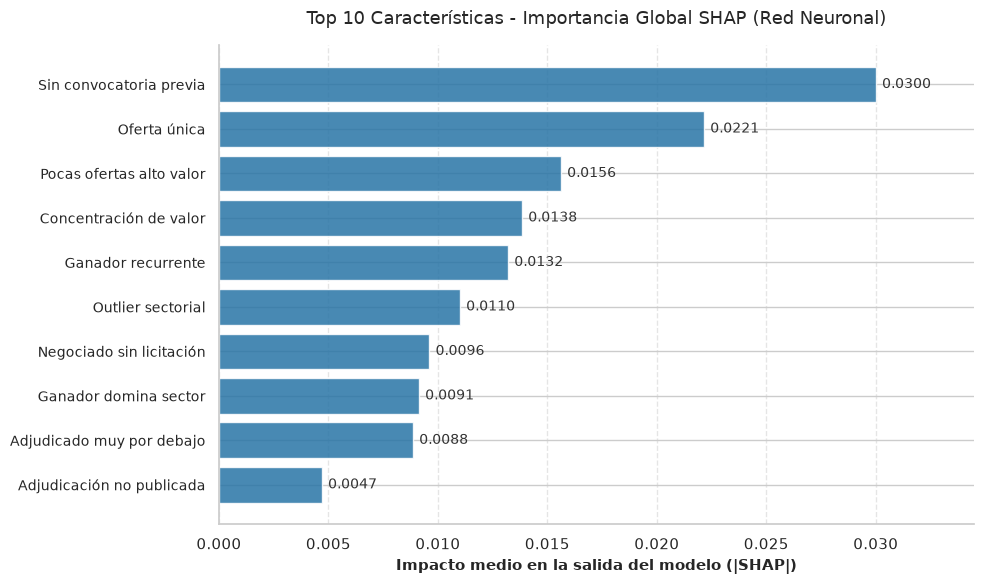

In [40]:
# Top 10 features por |SHAP| medio

# Valor absoluto medio por característica a lo largo de todas las muestras
importancia_media_shap = np.abs(valores_shap).mean(axis=0)

# Ordeno las características de mayor a menor impacto global
ranking_shap = sorted(zip(nombres_features_entrada, importancia_media_shap), key=lambda x: -x[1])

print("\n--- Top 10 características con mayor impacto en las predicciones ---")
for nombre, valor in ranking_shap[:10]:
    print(f"  {valor:.4f} | {nombre}")

# Gráfica
fig, ax = plt.subplots(figsize=(10, 6))

# Extraigo los 10 primeros y los invierto ([::-1]) para que el de mayor impacto quede arriba
nombres_top = [r[0] for r in ranking_shap[:10]][::-1]
valores_top = [r[1] for r in ranking_shap[:10]][::-1]

# Gráfico de barras horizontales (usando el mismo azul corporativo de las gráficas anteriores)
barras_shap = ax.barh(range(10), valores_top, color='#2874A6', edgecolor='white', alpha=0.85)

# Configuración del eje Y
ax.set_yticks(range(10))
ax.set_yticklabels(nombres_top, fontsize=10)

# Etiquetas y título
ax.set_xlabel('Impacto medio en la salida del modelo (|SHAP|)', fontsize=11, fontweight='bold')
ax.set_title('Top 10 Características - Importancia Global SHAP (Red Neuronal)', fontsize=13, pad=15)

# Limpieza visual y grid
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Añado el valor numérico exacto a la derecha de cada barra
for barra in barras_shap:
    ancho = barra.get_width()
    ax.text(ancho + (max(valores_top) * 0.01), barra.get_y() + barra.get_height()/2, 
            f'{ancho:.4f}', 
            va='center', ha='left', fontsize=10, color='#333333')

# Amplío un 15% el límite del eje X para que las etiquetas de texto no se salgan del gráfico
ax.set_xlim(0, max(valores_top) * 1.15)

plt.tight_layout()
plt.show()


---

## Fase 6 — Despliegue (demo de inferencia)

A continuación demuestro cómo usar el motor de inferencia con los modelos entrenados para puntuar adjudicaciones nuevas (un caso online y un batch de 1.000 filas).

In [41]:
import time
import json
import joblib
import numpy as np
import pandas as pd
from tensorflow import keras

# -------------------------------------------------------------------------
# FASE 6: Despliegue - Motor de Inferencia
# -------------------------------------------------------------------------
# En vez de hacer una clase, defino funciones sueltas que cargan los modelos
# y hacen la inferencia. Es mas sencillo y suficiente para el TFM.
print("Cargando modelos para inferencia...")

ruta_modelos = os.path.join(PROJ_ROOT, "models")

# Listas de variables (heredadas de fases anteriores)
VARIABLES_BINARIAS = tuple(c for c in columnas_features_ocde if c.startswith("RF_"))
VARIABLES_CONTINUAS = tuple(c for c in columnas_features_ocde if not c.startswith("RF_"))
TODAS_LAS_VARIABLES = VARIABLES_BINARIAS + VARIABLES_CONTINUAS
N_BINARIAS = len(VARIABLES_BINARIAS)
N_CONTINUAS = len(VARIABLES_CONTINUAS)

# Diccionario para poner nombres legibles a las red flags en el resultado
ETIQUETAS_FEATURES = {
    "RF_NO_PRIOR_NOTICE": "Sin convocatoria previa",
    "RF_NEGOTIATED_NO_CALL": "Negociado sin licitacion",
    "RF_AWARD_NO_PUBLICATION": "Adjudicacion no publicada",
    "RF_ACCELERATED": "Procedimiento acelerado",
    "RF_RESTRICTED": "Procedimiento restringido",
    "RF_INFO_UNPUBLISHED": "Informacion no publicada",
    "RF_MANY_CORRECTIONS": "Muchas correcciones",
    "RF_OUT_OF_DIRECTIVES": "Fuera de directivas",
    "RF_SINGLE_BID": "Oferta unica",
    "RF_ZERO_BIDS": "Sin ofertas",
    "RF_NO_CROSS_BORDER": "Sin competencia transfronteriza",
    "RF_FEW_BIDS_HIGH_VALUE": "Pocas ofertas alto valor",
    "RF_AWARD_BELOW_EST": "Adjudicado muy por debajo",
    "RF_AWARD_ABOVE_EST": "Adjudicado por encima",
    "RF_NEAR_THRESHOLD": "Cerca umbral publicidad",
    "RF_VALUE_OUTLIER_SECTOR": "Outlier sectorial",
    "RF_SELF_DEALING": "Autocontratacion",
    "RF_AWARDED_TO_GROUP": "Adjudicado a grupo",
    "RF_WINNER_OFF_COUNTRY": "Ganador fuera del pais",
    "RF_WINNER_RECURRENT_BUYER": "Ganador recurrente",
    "RF_WINNER_DOMINANT_SECTOR": "Ganador domina sector",
    "RF_WINNER_VALUE_CONCENTRATION": "Concentracion de valor",
    "RATIO_AWARD_EST": "Ratio adjudicado/estimado",
    "VALUE_DEV_SECTOR": "Desviacion sectorial",
    "WINNER_SHARE_BUYER": "Cuota ganador/comprador",
    "WINNER_SHARE_SECTOR": "Cuota ganador/sector",
    "WINNER_VALUE_SHARE_BUYER": "Cuota valor ganador/comprador",
}

UMBRAL_BAJO = 0.3
UMBRAL_ALTO = 0.7

# Cargo los modelos guardados
scaler_inf = joblib.load(os.path.join(ruta_modelos, "scaler.joblib"))
dnn_inf = keras.models.load_model(os.path.join(ruta_modelos, "dnn.keras"))
autoencoder_inf = keras.models.load_model(os.path.join(ruta_modelos, "autoencoder.keras"))
iforest_inf = joblib.load(os.path.join(ruta_modelos, "isolation_forest.joblib"))

# Para normalizar los scores entre 0 y 1 uso los cuantiles 1% y 99% del lote
# (igual que hice en las celdas de entrenamiento del AE y del IF)


def preprocesar_lote(df):
    """Convierte un DataFrame crudo en la matriz de 32 dims que necesitan Keras/IF."""
    df_temp = df.copy()

    # Si falta alguna columna la anyado con 0 (binarias) o NaN (continuas)
    for col in TODAS_LAS_VARIABLES:
        if col not in df_temp.columns:
            df_temp[col] = 0 if col.startswith("RF_") else np.nan

    # Aseguro que las continuas son numericas
    for col in VARIABLES_CONTINUAS:
        df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")

    raw = df_temp[list(TODAS_LAS_VARIABLES)].to_numpy()
    parte_binaria = raw[:, :N_BINARIAS].astype(np.float32)
    parte_continua = raw[:, N_BINARIAS:].astype(np.float32)

    # Mascara de nulos: 1 donde habia NaN, 0 donde no
    mascara_nulos = np.isnan(parte_continua).astype(np.float32)

    # Imputo con la media del entrenamiento (esta guardada en el scaler)
    medias_train = scaler_inf.mean_
    parte_continua_rellena = np.where(np.isnan(parte_continua), medias_train, parte_continua)

    # Escalo
    parte_continua_escalada = scaler_inf.transform(parte_continua_rellena)

    # Los NaN escalados se ponen a 0 (la mascara ya le dice a la red que faltaba)
    parte_continua_final = np.nan_to_num(parte_continua_escalada, nan=0.0)

    # Junto todo: binarias + continuas escaladas + mascara
    matriz = np.concatenate([parte_binaria, parte_continua_final, mascara_nulos], axis=1)
    return matriz.astype(np.float32)


def predecir(df):
    """Devuelve una lista de diccionarios con el score de riesgo de cada fila."""
    t0 = time.time()
    X = preprocesar_lote(df)

    # Score del DNN (modelo principal)
    scores_dnn = dnn_inf.predict(X, verbose=0, batch_size=4096).flatten()

    # Score del autoencoder: error de reconstruccion normalizado
    X_hat = autoencoder_inf.predict(X, verbose=0)
    mse = np.mean((X - X_hat) ** 2, axis=1)
    ae_lo, ae_hi = np.quantile(mse, 0.01), np.quantile(mse, 0.99)
    ae_rango = max(float(ae_hi - ae_lo), 1e-8)
    scores_ae = np.clip((mse - ae_lo) / ae_rango, 0.0, 1.0)

    # Score del isolation forest: score de anomalia normalizado
    raw_if = -iforest_inf.decision_function(X)
    if_lo, if_hi = np.quantile(raw_if, 0.01), np.quantile(raw_if, 0.99)
    if_rango = max(float(if_hi - if_lo), 1e-8)
    scores_if = np.clip((raw_if - if_lo) / if_rango, 0.0, 1.0)

    resultados = []
    for i in range(len(df)):
        fila = df.iloc[[i]]
        score_final = float(scores_dnn[i])

        # Miro que red flags estaban activas en esta fila
        banderas = []
        for col in VARIABLES_BINARIAS:
            if col in fila.columns and int(fila[col].iloc[0]) == 1:
                banderas.append({
                    "flag": col,
                    "descripcion": ETIQUETAS_FEATURES.get(col, col)
                })

        # Etiqueta de riesgo segun el umbral
        if score_final < UMBRAL_BAJO:
            etiqueta = "BAJO"
        elif score_final < UMBRAL_ALTO:
            etiqueta = "MEDIO"
        else:
            etiqueta = "ALTO"

        resultados.append({
            "riesgo_score": round(score_final, 4),
            "riesgo_etiqueta": etiqueta,
            "autoencoder_score": round(float(scores_ae[i]), 4),
            "iforest_score": round(float(scores_if[i]), 4),
            "modelo": "dnn_fusion",
            "num_banderas_activas": len(banderas),
            "top_banderas": banderas[:5],
            "latencia_ms": round((time.time() - t0) / max(len(df), 1) * 1000, 2),
        })

    return resultados


print("Modelos cargados: DNN + Autoencoder + Isolation Forest. Listo.")


Cargando modelos para inferencia...


Modelos cargados: DNN + Autoencoder + Isolation Forest. Listo.


In [42]:
# Caso 2: Adjudicacion de BAJO riesgo (sin red flags)
# Pongo todas las variables a 0 (ninguna red flag activa y continuas a 0)
caso_bajo = {col: 0 for col in TODAS_LAS_VARIABLES}

# Ajusto las metricas continuas a valores normales y competitivos
caso_bajo['RATIO_AWARD_EST'] = 0.95      # se adjudica un 5% por debajo del presupuesto
caso_bajo['WINNER_SHARE_BUYER'] = 0.20   # el ganador solo tiene el 20% de las compras del ente
caso_bajo['WINNER_SHARE_SECTOR'] = 0.15  # el ganador solo tiene un 15% de cuota de mercado

# Paso el diccionario como un DataFrame de una fila
resultado_bajo = predecir(pd.DataFrame([caso_bajo]))[0]

print("\n--- Respuesta del Motor (Payload JSON) ---")
print(json.dumps(resultado_bajo, indent=2, ensure_ascii=False))



--- Respuesta del Motor (Payload JSON) ---
{
  "riesgo_score": 0.0,
  "riesgo_etiqueta": "BAJO",
  "autoencoder_score": 0.0,
  "iforest_score": 0.0,
  "modelo": "dnn_fusion",
  "num_banderas_activas": 0,
  "top_banderas": [],
  "latencia_ms": 105.92
}


In [43]:
# Scoring batch sobre una muestra del parquet
# Cojo 1.000 adjudicaciones aleatorias
lote_prueba = features_pd.sample(n=1000, random_state=0)

# Inferencia con la funcion predecir
resultados_batch = predecir(lote_prueba)
df_resultados = pd.DataFrame(resultados_batch)

# Reporte de resultados
print("\n--- Distribucion de Riesgo (Muestra de 1.000 adjudicaciones) ---")
print(df_resultados['riesgo_etiqueta'].value_counts().to_string())

print(f"\n--- Resumen de Rendimiento y Metricas del Lote ---")
print(f"  -> Indice de Riesgo Medio (Score): {df_resultados['riesgo_score'].mean():.4f}")
print(f"  -> Latencia de Inferencia:         {df_resultados['latencia_ms'].mean():.2f} ms / prediccion")




--- Distribucion de Riesgo (Muestra de 1.000 adjudicaciones) ---
riesgo_etiqueta
BAJO    955
ALTO     45

--- Resumen de Rendimiento y Metricas del Lote ---
  -> Indice de Riesgo Medio (Score): 0.0450
  -> Latencia de Inferencia:         0.20 ms / prediccion


### Resumen final de resultados

- **Tablón consolidado**: 4.256.060 adjudicaciones (5,23% positivos según P95 de `RF_SCORE`).
- **Supervisado base (22 flags)**: DNN (AUROC 1,00) y Random Forest MLlib (AUROC 0,9979) reproducen la regla por acoplamiento estructural.
- **Validación sin circularidad**: El Experimento B (variables crudas + entity embeddings) alcanza AUROC 0,9846 y AUPRC 0,8292, consolidándose como la arquitectura supervisada principal.
- **Detección no supervisada**: El Autoencoder (AUROC 0,8566) queda como herramienta para detección de anomalías atípicas fuera de manual.



